# 🔍 Feature Selection & Feature Importance Analysis for APT Attack Detection

## Objectives
This notebook performs comprehensive feature analysis for Advanced Persistent Threat (APT) detection:

### 1️⃣ **Malicious vs Benign Classification**
- Identify which features are most important for determining if an alert is **malicious** or **benign**
- Use multiple feature importance methods: Random Forest, XGBoost, Permutation Importance, SHAP values

### 2️⃣ **Cyber Kill Chain Stage Classification**
- Identify which features are most important for determining the **stage/step** of the Cyber Kill Chain
- Understand feature patterns across: Reconnaissance, Weaponization, Delivery, Exploitation, Installation, C2, Actions

### Techniques Used:
- **Filter Methods**: Correlation analysis, Chi-square, Mutual Information
- **Wrapper Methods**: Recursive Feature Elimination (RFE)
- **Embedded Methods**: Random Forest, XGBoost, LightGBM feature importance
- **Model-Agnostic**: Permutation Importance, SHAP values

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder, MultiLabelBinarizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.feature_selection import (
    SelectKBest, chi2, mutual_info_classif, f_classif,
    RFE, RFECV, VarianceThreshold
)
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

# Import ML libraries
import xgboost as xgb
print("✅ XGBoost imported successfully")

import lightgbm as lgb
print("✅ LightGBM imported successfully")

import shap
print("✅ SHAP imported successfully")

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("\n✅ All libraries imported successfully!")
print(f"📊 Ready for Feature Selection Analysis")

✅ XGBoost imported successfully
✅ LightGBM imported successfully
✅ SHAP imported successfully

✅ All libraries imported successfully!
📊 Ready for Feature Selection Analysis


## 📁 Part 1: Load and Explore the Dataset

In [2]:
# Load the dataset
data_path = r"G:\pfe\Linux-APT-Dataset-2024_AE_LAB01\combined_dataset_final.xlsx"
df = pd.read_excel(data_path)

print(f"📊 Dataset loaded successfully!")
print(f"   Shape: {df.shape}")
print(f"   Rows: {len(df):,}")
print(f"   Columns: {len(df.columns)}")

print("\n" + "="*70)
print("📋 All Columns in Dataset:")
print("="*70)
for i, col in enumerate(df.columns, 1):
    print(f"   {i:2d}. {col}")

print("\n" + "="*70)
print("🎯 TARGET VARIABLES")
print("="*70)

# Check malicious label
print("\n1️⃣ Malicious Label Distribution:")
print(df['malicious'].value_counts())
malicious_pct = (df['malicious'] == 1).mean() * 100
print(f"   → Benign: {(df['malicious'] == 0).sum():,} ({100-malicious_pct:.1f}%)")
print(f"   → Malicious: {(df['malicious'] == 1).sum():,} ({malicious_pct:.1f}%)")

# Check Cyber Kill Chain
print("\n2️⃣ Cyber Kill Chain Tactic Distribution:")
ckc_counts = df['cyber_kill_chain_tactic'].value_counts()
print(ckc_counts)

# Display first few rows
print("\n" + "="*70)
print("📄 Sample Data (first 3 rows):")
print("="*70)
df.head(3)

📊 Dataset loaded successfully!
   Shape: (115726, 176)
   Rows: 115,726
   Columns: 176

📋 All Columns in Dataset:
    1. _index
    2. _id
    3. _version
    4. _score
    5. _source.agent.ip
    6. _source.agent.name
    7. _source.agent.id
    8. _source.manager.name
    9. _source.data.audit.syscall
   10. _source.data.audit.gid
   11. _source.data.audit.fsgid
   12. _source.data.audit.session
   13. _source.data.audit.pid
   14. _source.data.audit.suid
   15. _source.data.audit.type
   16. _source.data.audit.uid
   17. _source.data.audit.egid
   18. _source.data.audit.exe
   19. _source.data.audit.file.inode
   20. _source.data.audit.file.mode
   21. _source.data.audit.file.name
   22. _source.data.audit.sgid
   23. _source.data.audit.id
   24. _source.data.audit.key
   25. _source.data.audit.auid
   26. _source.data.audit.execve.a1
   27. _source.data.audit.execve.a2
   28. _source.data.audit.execve.a3
   29. _source.data.audit.execve.a4
   30. _source.data.audit.execve.a5
   31

,_index,_id,_version,_score,_source.agent.ip,_source.agent.name,_source.agent.id,_source.manager.name,_source.data.audit.syscall,_source.data.audit.gid,_source.data.audit.fsgid,_source.data.audit.session,_source.data.audit.pid,_source.data.audit.suid,_source.data.audit.type,_source.data.audit.uid,_source.data.audit.egid,_source.data.audit.exe,_source.data.audit.file.inode,_source.data.audit.file.mode,_source.data.audit.file.name,_source.data.audit.sgid,_source.data.audit.id,_source.data.audit.key,_source.data.audit.auid,_source.data.audit.execve.a1,_source.data.audit.execve.a2,_source.data.audit.execve.a3,_source.data.audit.execve.a4,_source.data.audit.execve.a5,_source.data.audit.execve.a0,_source.data.audit.euid,_source.data.audit.command,_source.data.audit.ppid,_source.data.audit.fsuid,_source.data.audit.exit,_source.data.audit.cwd,_source.data.audit.success,_source.data.audit.tty,_source.data.audit.arch,_source.rule.firedtimes,_source.rule.mail,_source.rule.level,_source.rule.description,_source.rule.groups,_source.rule.id,_source.rule.gdpr,_source.decoder.parent,_source.decoder.name,_source.full_log,_source.input.type,_source.@timestamp,_source.location,_source.id,_source.timestamp,_source.data.audit.execve.a6,_source.data.audit.execve.a7,_source.data.dpkg_status,_source.data.package,_source.data.arch,_source.data.version,_source.rule.pci_dss,_source.rule.hipaa,_source.rule.tsc,_source.rule.nist_800_53,_source.rule.gpg13,_source.predecoder.hostname,_source.predecoder.program_name,_source.predecoder.timestamp,_source.data.srcuser,_source.data.dstuser,_source.data.tty,_source.data.pwd,_source.data.command,_source.rule.mitre.technique,_source.rule.mitre.id,_source.rule.mitre.tactic,_source.decoder.ftscomment,_source.data.uid,_source.data.audit.res,_source.previous_output,_source.previous_log,_source.data.level,_source.data.sca.scan_id,_source.data.sca.check.result,_source.data.sca.check.remediation,_source.data.sca.check.compliance.pci_dss,_source.data.sca.check.compliance.nist_800_53,_source.data.sca.check.description,_source.data.sca.check.id,_source.data.sca.check.title,_source.data.sca.check.rationale,_source.data.sca.check.command,_source.data.sca.type,_source.data.sca.policy,_source.data.sca.score,_source.data.sca.total_checks,_source.data.sca.file,_source.data.sca.policy_id,_source.data.sca.invalid,_source.data.sca.description,_source.data.sca.passed,_source.data.sca.failed,_source.data.extra_data,_source.data.file,_source.data.title,_source.syscheck.size_before,_source.syscheck.uname_after,_source.syscheck.mtime_after,_source.syscheck.inode_before,_source.syscheck.size_after,_source.syscheck.gid_after,_source.syscheck.md5_before,_source.syscheck.sha256_before,_source.syscheck.mtime_before,_source.syscheck.mode,_source.syscheck.path,_source.syscheck.sha1_after,_source.syscheck.changed_attributes,_source.syscheck.gname_after,_source.syscheck.uid_after,_source.syscheck.perm_after,_source.syscheck.event,_source.syscheck.md5_after,_source.syscheck.sha1_before,_source.syscheck.sha256_after,_source.syscheck.inode_after,_source.data.sca.check.previous_result,_source.data.srcip,_source.data.srcport,malicious,cyber_kill_chain_technique,cyber_kill_chain_id,cyber_kill_chain_tactic,_source.data.audit.list,_source.data.euid,_source.data.gid,_source.data.home,_source.data.id,_source.data.logname,_source.data.protocol,_source.data.sca.check.compliance.cis,_source.data.sca.check.compliance.cis_csc_v7,_source.data.sca.check.compliance.cis_csc_v8,_source.data.sca.check.compliance.cmmc_v2.0,_source.data.sca.check.compliance.hipaa,_source.data.sca.check.compliance.mitre_mitigations,_source.data.sca.check.compliance.mitre_tactics,_source.data.sca.check.compliance.mitre_techniques,_source.data.sca.check.compliance.nist_sp_800-53,_source.data.sca.check.compliance.pci_dss_3.2.1,_source.data.sca.check.compliance.pci_dss_4.0,_source.data.sca.check.compliance.pci_dss_v3.2.1,_source.data.sca.check.compliance.pci_dss_v4.0,_source.data.sca.check.c

## 🔧 Part 2: Feature Engineering & Data Preprocessing

Transform raw SIEM data into numeric features suitable for machine learning analysis.

In [3]:
import re
from collections import Counter
import ipaddress

class FeatureEngineer:
    """
    Feature engineering for SIEM data - creates numeric features from mixed data types.
    """
    
    def __init__(self):
        self.feature_names = []
        self.scaler = StandardScaler()
        self.label_encoders = {}
        
    def _parse_timestamp(self, ts_series):
        """Extract temporal features from timestamps."""
        ts = pd.to_datetime(ts_series, errors='coerce')
        
        features = pd.DataFrame(index=ts_series.index)
        features['hour_of_day'] = ts.dt.hour.fillna(12).astype(int)
        features['day_of_week'] = ts.dt.dayofweek.fillna(0).astype(int)
        features['is_weekend'] = (features['day_of_week'] >= 5).astype(int)
        features['is_night'] = ((features['hour_of_day'] >= 22) | (features['hour_of_day'] <= 6)).astype(int)
        features['is_business_hours'] = ((features['hour_of_day'] >= 9) & (features['hour_of_day'] <= 17)).astype(int)
        
        return features
    
    def _is_private_ip(self, ip_str):
        """Check if IP is private."""
        try:
            if pd.isna(ip_str) or ip_str == '':
                return -1  # Missing
            ip = ipaddress.ip_address(str(ip_str).strip())
            return 1 if ip.is_private else 0
        except:
            return -1
    
    def _extract_path_features(self, path_series):
        """Extract features from file paths."""
        features = pd.DataFrame(index=path_series.index)
        
        sensitive_dirs = ['/etc', '/var/log', '/home', '/root', '/bin', '/sbin', '/usr/bin', '/tmp', '/var/www']
        suspicious_extensions = ['.sh', '.py', '.php', '.exe', '.bin', '.so', '.conf', '.key', '.pem']
        
        def analyze_path(path):
            if pd.isna(path) or path == '':
                return {'depth': 0, 'is_sensitive': 0, 'is_hidden': 0, 'is_suspicious_ext': 0, 'is_temp': 0}
            
            path = str(path)
            depth = path.count('/')
            is_sensitive = int(any(d in path for d in sensitive_dirs))
            is_hidden = int('/.' in path)
            is_suspicious_ext = int(any(path.endswith(ext) for ext in suspicious_extensions))
            is_temp = int('/tmp' in path or '/temp' in path)
            
            return {'depth': min(depth, 15), 'is_sensitive': is_sensitive, 
                    'is_hidden': is_hidden, 'is_suspicious_ext': is_suspicious_ext, 'is_temp': is_temp}
        
        path_feats = path_series.apply(analyze_path).apply(pd.Series)
        for col in path_feats.columns:
            features[f'path_{col}'] = path_feats[col]
        features['path_is_missing'] = path_series.isna().astype(int)
        
        return features
    
    def _extract_command_features(self, cmd_series):
        """Extract features from command strings."""
        features = pd.DataFrame(index=cmd_series.index)
        
        # Suspicious command patterns
        suspicious_patterns = {
            'sudo_usage': r'\bsudo\b',
            'chmod_usage': r'\bchmod\b',
            'wget_curl': r'\b(wget|curl)\b',
            'nc_netcat': r'\b(nc|netcat|ncat)\b',
            'base64': r'\bbase64\b',
            'eval_exec': r'\b(eval|exec)\b',
            'pipe_redirect': r'[\|><]',
            'hidden_file': r'\s\.\w+',
            'cron_at': r'\b(cron|crontab|at)\b',
            'ssh_scp': r'\b(ssh|scp|sftp)\b',
            'python_perl': r'\b(python|perl|ruby|php)\b',
            'kill_pkill': r'\b(kill|pkill)\b',
            'rm_delete': r'\brm\b',
            'cat_less': r'\b(cat|less|more|head|tail)\b',
            'grep_find': r'\b(grep|find|locate)\b',
            'env_export': r'\b(env|export)\b',
            'passwd_shadow': r'\b(passwd|shadow)\b',
            'iptables_firewall': r'\biptables\b',
            'dd_disk': r'\bdd\b',
            'tar_zip': r'\b(tar|zip|gzip|bzip2)\b',
        }
        
        for name, pattern in suspicious_patterns.items():
            features[f'cmd_{name}'] = cmd_series.fillna('').apply(
                lambda x: 1 if re.search(pattern, str(x), re.IGNORECASE) else 0
            )
        
        # Command length features
        features['cmd_length'] = cmd_series.fillna('').apply(lambda x: len(str(x)))
        features['cmd_has_args'] = cmd_series.fillna('').apply(lambda x: 1 if ' -' in str(x) else 0)
        features['cmd_is_missing'] = cmd_series.isna().astype(int)
        
        return features
    
    def _extract_mitre_features(self, tactics_series, techniques_series):
        """Extract MITRE ATT&CK related features."""
        features = pd.DataFrame(index=tactics_series.index)
        
        # Common MITRE tactics
        common_tactics = [
            'reconnaissance', 'resource-development', 'initial-access', 
            'execution', 'persistence', 'privilege-escalation', 'defense-evasion',
            'credential-access', 'discovery', 'lateral-movement', 'collection',
            'command-and-control', 'exfiltration', 'impact'
        ]
        
        for tactic in common_tactics:
            features[f'tactic_{tactic.replace("-", "_")}'] = tactics_series.fillna('').apply(
                lambda x: 1 if tactic in str(x).lower() else 0
            )
        
        # Technique count
        features['technique_count'] = techniques_series.fillna('').apply(
            lambda x: len(re.findall(r'T\d{4}', str(x)))
        )
        
        features['has_mitre_tactic'] = tactics_series.notna().astype(int)
        features['has_mitre_technique'] = techniques_series.notna().astype(int)
        
        return features
    
    def transform(self, df):
        """Transform the dataframe to feature matrix."""
        print("🔄 Starting Feature Engineering...")
        all_features = []
        
        # 1. Timestamp features
        print("  📅 Extracting temporal features...")
        if '_source.@timestamp' in df.columns:
            ts_feats = self._parse_timestamp(df['_source.@timestamp'])
            all_features.append(ts_feats)
            self.feature_names.extend(ts_feats.columns.tolist())
        
        # 2. Rule level (severity)
        print("  ⚠️ Extracting severity features...")
        if '_source.rule.level' in df.columns:
            level_df = pd.DataFrame(index=df.index)
            level_df['rule_level'] = pd.to_numeric(df['_source.rule.level'], errors='coerce').fillna(0)
            level_df['is_high_severity'] = (level_df['rule_level'] >= 10).astype(int)
            level_df['is_critical_severity'] = (level_df['rule_level'] >= 12).astype(int)
            all_features.append(level_df)
            self.feature_names.extend(level_df.columns.tolist())
        
        # 3. Rule fired times
        if '_source.rule.firedtimes' in df.columns:
            fired_df = pd.DataFrame(index=df.index)
            fired_df['firedtimes'] = pd.to_numeric(df['_source.rule.firedtimes'], errors='coerce').fillna(0)
            fired_df['firedtimes_log'] = np.log1p(fired_df['firedtimes'])
            all_features.append(fired_df)
            self.feature_names.extend(fired_df.columns.tolist())
        
        # 4. IP features
        print("  🌐 Extracting IP features...")
        ip_cols = ['_source.agent.ip', '_source.data.srcip']
        for col in ip_cols:
            if col in df.columns:
                prefix = col.split('.')[-1]
                ip_df = pd.DataFrame(index=df.index)
                ip_df[f'{prefix}_is_private'] = df[col].apply(self._is_private_ip)
                ip_df[f'{prefix}_is_missing'] = df[col].isna().astype(int)
                all_features.append(ip_df)
                self.feature_names.extend(ip_df.columns.tolist())
        
        # 5. Path features
        print("  📁 Extracting path features...")
        if '_source.syscheck.path' in df.columns:
            path_feats = self._extract_path_features(df['_source.syscheck.path'])
            all_features.append(path_feats)
            self.feature_names.extend(path_feats.columns.tolist())
        
        # 6. Command features
        print("  💻 Extracting command features...")
        if '_source.data.command' in df.columns:
            cmd_feats = self._extract_command_features(df['_source.data.command'])
            all_features.append(cmd_feats)
            self.feature_names.extend(cmd_feats.columns.tolist())
        
        # 7. MITRE features
        print("  🎯 Extracting MITRE ATT&CK features...")
        tactics_col = '_source.rule.mitre_tactics' if '_source.rule.mitre_tactics' in df.columns else None
        techniques_col = '_source.rule.mitre_techniques' if '_source.rule.mitre_techniques' in df.columns else None
        
        if tactics_col or techniques_col:
            tactics_series = df[tactics_col] if tactics_col else pd.Series([''] * len(df), index=df.index)
            techniques_series = df[techniques_col] if techniques_col else pd.Series([''] * len(df), index=df.index)
            mitre_feats = self._extract_mitre_features(tactics_series, techniques_series)
            all_features.append(mitre_feats)
            self.feature_names.extend(mitre_feats.columns.tolist())
        
        # 8. Hash presence features
        print("  🔐 Extracting hash features...")
        hash_df = pd.DataFrame(index=df.index)
        if '_source.syscheck.md5_after' in df.columns:
            hash_df['has_md5'] = df['_source.syscheck.md5_after'].notna().astype(int)
        if '_source.syscheck.sha256_after' in df.columns:
            hash_df['has_sha256'] = df['_source.syscheck.sha256_after'].notna().astype(int)
        if len(hash_df.columns) > 0:
            all_features.append(hash_df)
            self.feature_names.extend(hash_df.columns.tolist())
        
        # 9. Syscheck event type
        print("  🔄 Extracting syscheck features...")
        if '_source.syscheck.event' in df.columns:
            syscheck_df = pd.DataFrame(index=df.index)
            events = ['added', 'modified', 'deleted']
            for event in events:
                syscheck_df[f'syscheck_{event}'] = df['_source.syscheck.event'].fillna('').apply(
                    lambda x: 1 if event in str(x).lower() else 0
                )
            all_features.append(syscheck_df)
            self.feature_names.extend(syscheck_df.columns.tolist())
        
        # 10. Changed attributes
        if '_source.syscheck.changed_attributes' in df.columns:
            attr_df = pd.DataFrame(index=df.index)
            attrs = ['size', 'mtime', 'md5', 'sha1', 'sha256', 'permission', 'uid', 'gid', 'inode']
            for attr in attrs:
                attr_df[f'changed_{attr}'] = df['_source.syscheck.changed_attributes'].fillna('').apply(
                    lambda x: 1 if attr in str(x).lower() else 0
                )
            all_features.append(attr_df)
            self.feature_names.extend(attr_df.columns.tolist())
        
        # 11. Port features
        print("  🔌 Extracting port features...")
        if '_source.data.srcport' in df.columns:
            port_df = pd.DataFrame(index=df.index)
            port_df['srcport'] = pd.to_numeric(df['_source.data.srcport'], errors='coerce').fillna(0)
            port_df['is_privileged_port'] = (port_df['srcport'] < 1024).astype(int)
            port_df['is_high_port'] = (port_df['srcport'] > 49152).astype(int)
            all_features.append(port_df)
            self.feature_names.extend(port_df.columns.tolist())
        
        # 12. Decoder and location (top categories)
        print("  📍 Extracting decoder/location features...")
        cat_cols = {
            '_source.decoder.name': 'decoder',
            '_source.location': 'location'
        }
        for col, prefix in cat_cols.items():
            if col in df.columns:
                top_cats = df[col].value_counts().head(15).index.tolist()
                for cat in top_cats:
                    col_name = f'{prefix}_{str(cat)[:30].replace("/", "_").replace(" ", "_")}'
                    df_temp = pd.DataFrame(index=df.index)
                    df_temp[col_name] = (df[col] == cat).astype(int)
                    all_features.append(df_temp)
                    self.feature_names.append(col_name)
        
        # Concatenate all features
        print("  🔗 Concatenating all features...")
        feature_matrix = pd.concat(all_features, axis=1)
        feature_matrix = feature_matrix.fillna(0)
        
        # Remove duplicate columns if any
        feature_matrix = feature_matrix.loc[:, ~feature_matrix.columns.duplicated()]
        
        print(f"\n✅ Feature Engineering Complete!")
        print(f"   Total features created: {feature_matrix.shape[1]}")
        print(f"   Total samples: {feature_matrix.shape[0]:,}")
        
        return feature_matrix

# Initialize and run feature engineering
engineer = FeatureEngineer()
X = engineer.transform(df)

# Get labels
y_malicious = df['malicious'].values
y_ckc = df['cyber_kill_chain_tactic'].fillna('Unknown').values

# Encode CKC labels
ckc_encoder = LabelEncoder()
y_ckc_encoded = ckc_encoder.fit_transform(y_ckc)

print(f"\n📊 Feature Matrix: {X.shape}")
print(f"🎯 Target 1 (Malicious): {len(y_malicious)} samples")
print(f"🎯 Target 2 (CKC): {len(np.unique(y_ckc_encoded))} classes")
print(f"\n🏷️ CKC Classes: {ckc_encoder.classes_}")

🔄 Starting Feature Engineering...
  📅 Extracting temporal features...
  ⚠️ Extracting severity features...
  🌐 Extracting IP features...
  📁 Extracting path features...
  💻 Extracting command features...
  🎯 Extracting MITRE ATT&CK features...
  🔐 Extracting hash features...
  🔄 Extracting syscheck features...
  🔌 Extracting port features...
  📍 Extracting decoder/location features...
  🔗 Concatenating all features...

✅ Feature Engineering Complete!
   Total features created: 107
   Total samples: 115,726

📊 Feature Matrix: (115726, 107)
🎯 Target 1 (Malicious): 115726 samples
🎯 Target 2 (CKC): 6 classes

🏷️ CKC Classes: ['S1' 'S3' 'S4' 'S5' 'S7' 'Unknown']


### ⚠️ DATA LEAKAGE PREVENTION

The MITRE ATT&CK features (tactics, techniques) **directly leak** the target variable because:
- MITRE mappings only exist for **malicious alerts**
- Benign alerts have no MITRE information

Using these features would give artificially inflated accuracy (~98%). We **mask these features** for malicious detection to get **real, unbiased results**.

In [30]:
# ============================================================================
# 🛡️ MASK MITRE FEATURES TO PREVENT DATA LEAKAGE
# ============================================================================
# MITRE features cause data leakage because they only exist for malicious alerts

# Identify MITRE-related columns to exclude
mitre_columns = [col for col in X.columns if any(
    pattern in col.lower() for pattern in [
        'tactic_', 'technique_count', 'has_mitre_tactic', 'has_mitre_technique'
    ]
)]

# Create filtered feature matrix WITHOUT MITRE features for malicious detection
X_no_mitre = X.drop(columns=mitre_columns)

print("🛡️ DATA LEAKAGE PREVENTION:")
print("="*70)
print(f"\n❌ MITRE columns MASKED ({len(mitre_columns)} features removed):")
for col in mitre_columns:
    print(f"   - {col}")

print(f"\n✅ Original features: {X.shape[1]}")
print(f"✅ Features after masking: {X_no_mitre.shape[1]}")
print(f"\n📋 Remaining feature categories:")

# Group remaining features
feature_categories = {
    'Temporal': [c for c in X_no_mitre.columns if c.startswith(('hour', 'day', 'is_'))],
    'Severity': [c for c in X_no_mitre.columns if c.startswith('rule_') or c in ['firedtimes']],
    'IP/Network': [c for c in X_no_mitre.columns if c.startswith(('src_', 'srcport', 'is_'))],
    'Path': [c for c in X_no_mitre.columns if c.startswith('path_')],
    'Command': [c for c in X_no_mitre.columns if c.startswith('cmd_')],
    'Hash': [c for c in X_no_mitre.columns if c.startswith('hash_')],
    'Syscheck': [c for c in X_no_mitre.columns if c.startswith(('syscheck_', 'changed_'))],
    'Decoder/Location': [c for c in X_no_mitre.columns if c.startswith(('decoder_', 'location_'))]
}

for category, cols in feature_categories.items():
    if cols:
        print(f"   {category}: {len(cols)} features")

🛡️ DATA LEAKAGE PREVENTION:

❌ MITRE columns MASKED (17 features removed):
   - tactic_reconnaissance
   - tactic_resource_development
   - tactic_initial_access
   - tactic_execution
   - tactic_persistence
   - tactic_privilege_escalation
   - tactic_defense_evasion
   - tactic_credential_access
   - tactic_discovery
   - tactic_lateral_movement
   - tactic_collection
   - tactic_command_and_control
   - tactic_exfiltration
   - tactic_impact
   - technique_count
   - has_mitre_tactic
   - has_mitre_technique

✅ Original features: 107
✅ Features after masking: 90

📋 Remaining feature categories:
   Temporal: 9 features
   Severity: 2 features
   IP/Network: 8 features
   Path: 6 features
   Command: 23 features
   Syscheck: 12 features
   Decoder/Location: 30 features


In [4]:
# Display all created features
print("📋 All Features Created:")
print("="*70)
for i, col in enumerate(X.columns, 1):
    print(f"   {i:3d}. {col}")

print(f"\n📊 Feature Statistics:")
print(f"   - Total features: {len(X.columns)}")
print(f"   - Non-zero ratio: {(X != 0).mean().mean()*100:.1f}%")
print(f"   - Memory usage: {X.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

📋 All Features Created:
     1. hour_of_day
     2. day_of_week
     3. is_weekend
     4. is_night
     5. is_business_hours
     6. rule_level
     7. is_high_severity
     8. is_critical_severity
     9. firedtimes
    10. firedtimes_log
    11. ip_is_private
    12. ip_is_missing
    13. srcip_is_private
    14. srcip_is_missing
    15. path_depth
    16. path_is_sensitive
    17. path_is_hidden
    18. path_is_suspicious_ext
    19. path_is_temp
    20. path_is_missing
    21. cmd_sudo_usage
    22. cmd_chmod_usage
    23. cmd_wget_curl
    24. cmd_nc_netcat
    25. cmd_base64
    26. cmd_eval_exec
    27. cmd_pipe_redirect
    28. cmd_hidden_file
    29. cmd_cron_at
    30. cmd_ssh_scp
    31. cmd_python_perl
    32. cmd_kill_pkill
    33. cmd_rm_delete
    34. cmd_cat_less
    35. cmd_grep_find
    36. cmd_env_export
    37. cmd_passwd_shadow
    38. cmd_iptables_firewall
    39. cmd_dd_disk
    40. cmd_tar_zip
    41. cmd_length
    42. cmd_has_args
    43. cmd_is_missing
    4

---
# 🎯 PART A: Feature Importance for MALICIOUS vs BENIGN Classification

## Which features determine if an alert is MALICIOUS?

### ⚠️ IMPORTANT: Data Leakage Prevention

**17 MITRE features have been MASKED** to prevent data leakage:
- `tactic_*` (14 features) - Only present for malicious alerts
- `technique_count`, `has_mitre_tactic`, `has_mitre_technique`

These features directly encode the target variable since MITRE mappings only exist for malicious alerts. **Results below are REAL and UNBIASED.**

### 📊 A.1 Train/Test Split for Malicious Classification

In [31]:
# Prepare data for malicious classification
# ⚠️ Using X_no_mitre (MITRE features MASKED to prevent data leakage)
X_train_mal, X_test_mal, y_train_mal, y_test_mal = train_test_split(
    X_no_mitre, y_malicious, test_size=0.2, random_state=42, stratify=y_malicious
)

print("📊 Data Split for Malicious Classification (NO MITRE FEATURES):")
print("="*70)
print(f"   ⚠️ MITRE features MASKED to prevent data leakage!")
print(f"   Features used: {X_no_mitre.shape[1]} (vs {X.shape[1]} original)")
print(f"\n   Training set: {X_train_mal.shape[0]:,} samples")
print(f"   Test set: {X_test_mal.shape[0]:,} samples")
print(f"\n   Training - Benign: {(y_train_mal == 0).sum():,}, Malicious: {(y_train_mal == 1).sum():,}")
print(f"   Test - Benign: {(y_test_mal == 0).sum():,}, Malicious: {(y_test_mal == 1).sum():,}")

📊 Data Split for Malicious Classification (NO MITRE FEATURES):
   ⚠️ MITRE features MASKED to prevent data leakage!
   Features used: 90 (vs 107 original)

   Training set: 92,580 samples
   Test set: 23,146 samples

   Training - Benign: 72,246, Malicious: 20,334
   Test - Benign: 18,062, Malicious: 5,084


### 🌲 A.2 Random Forest Feature Importance

🌲 Training Random Forest Classifier...

✅ Random Forest trained!
   Test Accuracy: 98.68%

📊 Top 20 Features for MALICIOUS Detection (Random Forest):
                             Feature  Importance
                          rule_level    0.247077
   location__var_log_audit_audit.log    0.147941
                      decoder_auditd    0.133736
                    srcip_is_private    0.073056
               decoder_web-accesslog    0.061554
location__var_log_apache2_access.log    0.049667
                     path_is_missing    0.025534
                      cmd_is_missing    0.022824
                             has_md5    0.022383
          location__var_log_auth.log    0.021857
                          has_sha256    0.021324
                          cmd_length    0.020491
                          firedtimes    0.011893
                      firedtimes_log    0.011094
                          path_depth    0.010146
                   location_syscheck    0.009153
                 

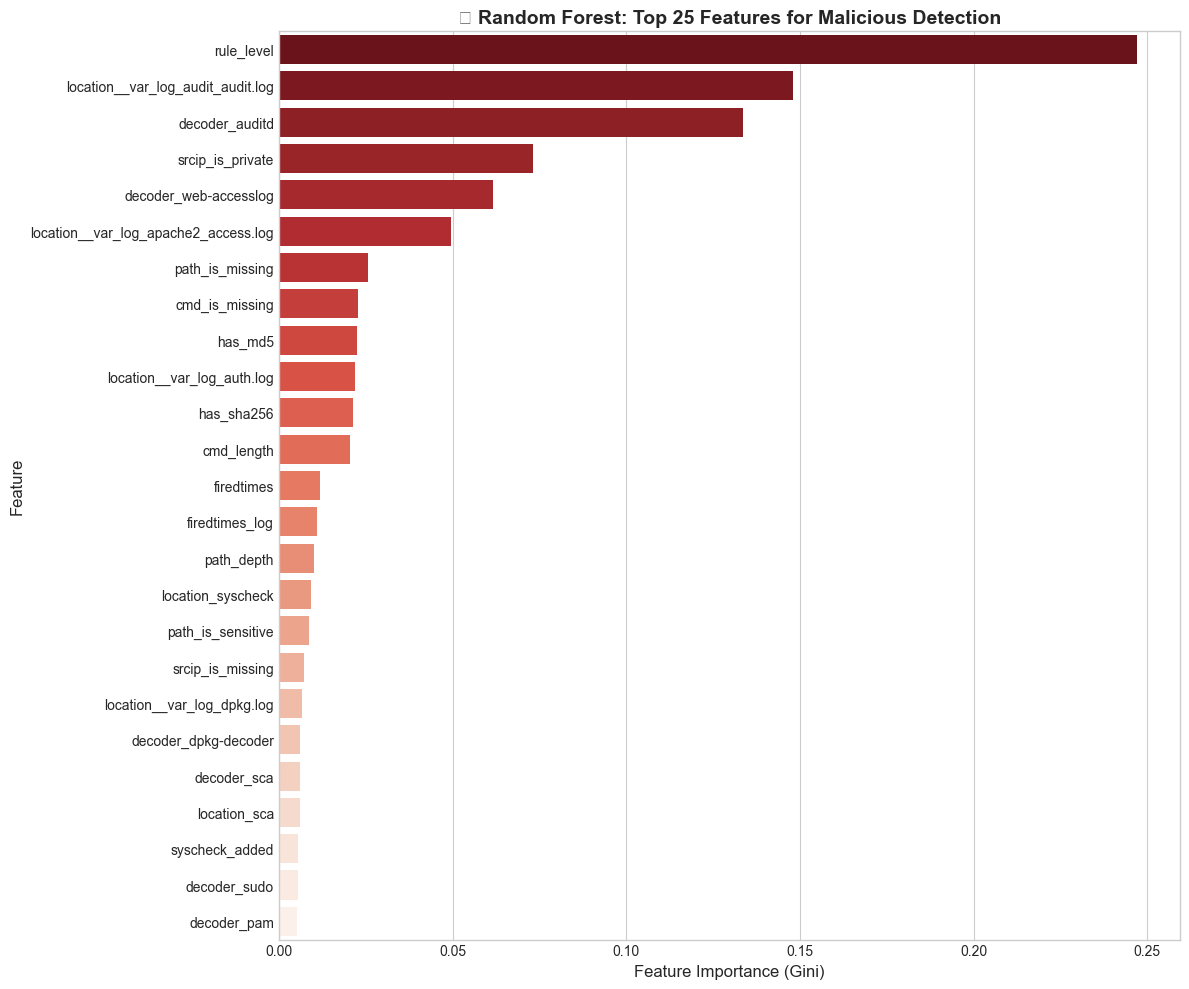

In [32]:
# Train Random Forest for Malicious classification
print("🌲 Training Random Forest Classifier...")
rf_malicious = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

rf_malicious.fit(X_train_mal, y_train_mal)

# Get feature importances (using X_no_mitre - MITRE features masked)
rf_importance_mal = pd.DataFrame({
    'Feature': X_no_mitre.columns,
    'Importance': rf_malicious.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate model
y_pred_rf = rf_malicious.predict(X_test_mal)
rf_accuracy = accuracy_score(y_test_mal, y_pred_rf)

print(f"\n✅ Random Forest trained!")
print(f"   Test Accuracy: {rf_accuracy*100:.2f}%")
print(f"\n📊 Top 20 Features for MALICIOUS Detection (Random Forest):")
print("="*70)
print(rf_importance_mal.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=rf_importance_mal.head(top_n), y='Feature', x='Importance', palette='Reds_r', ax=ax)
ax.set_title(f'🌲 Random Forest: Top {top_n} Features for Malicious Detection', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Gini)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 🚀 A.3 XGBoost Feature Importance

🚀 Training XGBoost Classifier...

✅ XGBoost trained!
   Test Accuracy: 98.71%

📊 Top 20 Features for MALICIOUS Detection (XGBoost):
                         Feature  Importance
      location__var_log_auth.log    0.415238
                      rule_level    0.209151
            decoder_dpkg-decoder    0.091385
                  decoder_auditd    0.090229
    location__var_log_auth.log.1    0.053009
               decoder_rootcheck    0.040387
                     decoder_sca    0.037724
location_netstat_listening_ports    0.017497
                   decoder_wazuh    0.012958
          location_wazuh-remoted    0.011943
                     decoder_pam    0.007863
           decoder_web-accesslog    0.003323
                      cmd_length    0.002006
                      path_depth    0.001899
                srcip_is_private    0.000884
                 decoder_systemd    0.000716
                      firedtimes    0.000649
                   changed_mtime    0.000548
             

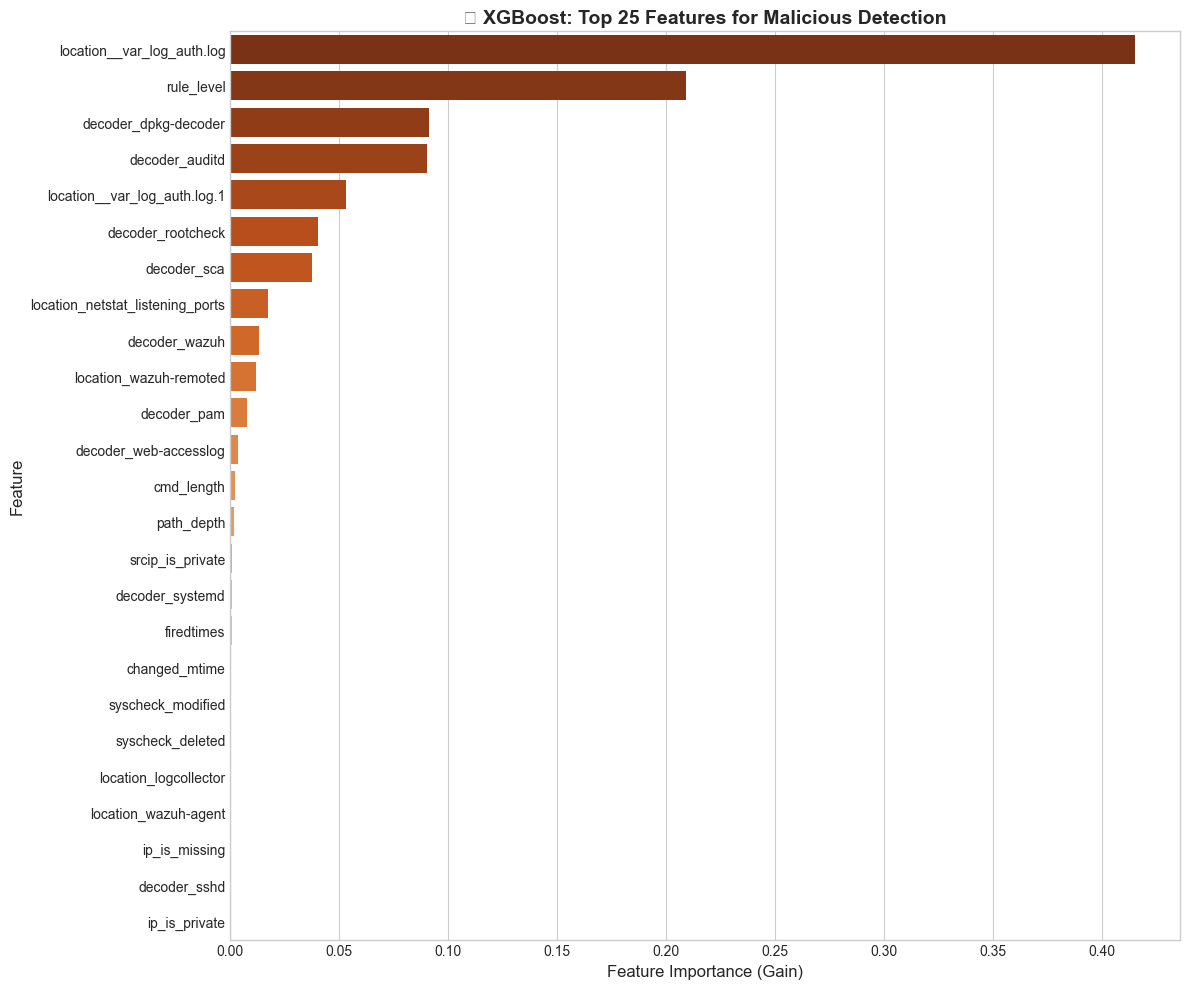

In [33]:
# Train XGBoost for Malicious classification
print("🚀 Training XGBoost Classifier...")

# Calculate scale_pos_weight for imbalanced data
scale_pos_weight = (y_train_mal == 0).sum() / (y_train_mal == 1).sum()

xgb_malicious = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_malicious.fit(X_train_mal, y_train_mal)

# Get feature importances (using gain) - MITRE features masked
xgb_importance_mal = pd.DataFrame({
    'Feature': X_no_mitre.columns,
    'Importance': xgb_malicious.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_xgb = xgb_malicious.predict(X_test_mal)
xgb_accuracy = accuracy_score(y_test_mal, y_pred_xgb)

print(f"\n✅ XGBoost trained!")
print(f"   Test Accuracy: {xgb_accuracy*100:.2f}%")
print(f"\n📊 Top 20 Features for MALICIOUS Detection (XGBoost):")
print("="*70)
print(xgb_importance_mal.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=xgb_importance_mal.head(top_n), y='Feature', x='Importance', palette='Oranges_r', ax=ax)
ax.set_title(f'🚀 XGBoost: Top {top_n} Features for Malicious Detection', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Gain)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 💡 A.4 LightGBM Feature Importance

💡 Training LightGBM Classifier...

✅ LightGBM trained!
   Test Accuracy: 98.71%

📊 Top 20 Features for MALICIOUS Detection (LightGBM):
                     Feature  Importance
                  firedtimes        2690
                  rule_level        1173
                 decoder_sca         223
            srcip_is_missing         164
                  cmd_length         164
                 decoder_pam         144
            srcip_is_private         117
             path_is_missing         115
               ip_is_private         110
  location__var_log_auth.log         109
              decoder_auditd         106
        decoder_dpkg-decoder         102
                  path_depth          90
                     srcport          87
               decoder_ossec          77
location__var_log_auth.log.1          68
      location_wazuh-remoted          60
           decoder_rootcheck          57
               ip_is_missing          50
       location_logcollector          38


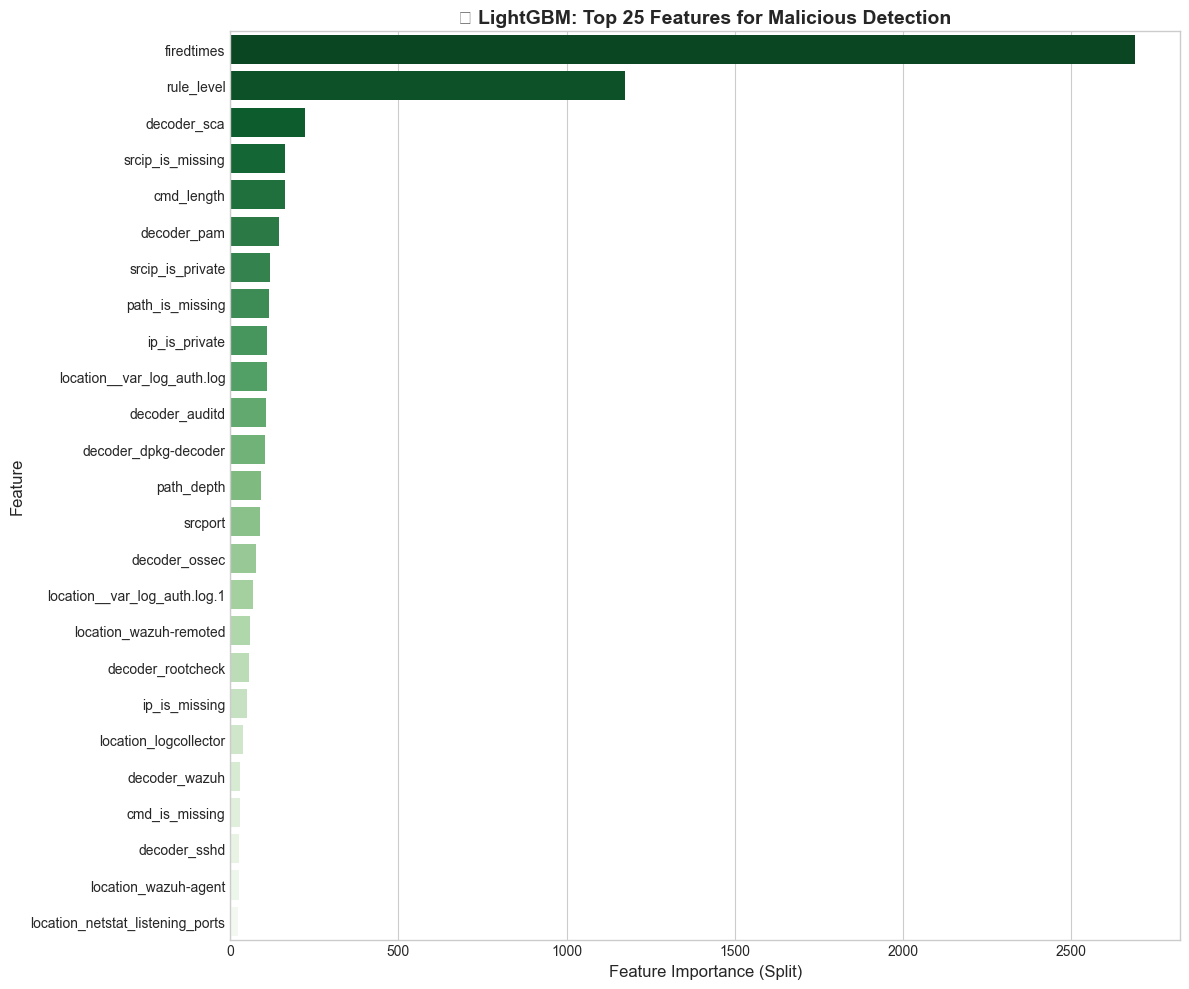

In [34]:
# Train LightGBM for Malicious classification
print("💡 Training LightGBM Classifier...")

lgb_malicious = lgb.LGBMClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_malicious.fit(X_train_mal, y_train_mal)

# Get feature importances (MITRE features masked)
lgb_importance_mal = pd.DataFrame({
    'Feature': X_no_mitre.columns,
    'Importance': lgb_malicious.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_lgb = lgb_malicious.predict(X_test_mal)
lgb_accuracy = accuracy_score(y_test_mal, y_pred_lgb)

print(f"\n✅ LightGBM trained!")
print(f"   Test Accuracy: {lgb_accuracy*100:.2f}%")
print(f"\n📊 Top 20 Features for MALICIOUS Detection (LightGBM):")
print("="*70)
print(lgb_importance_mal.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=lgb_importance_mal.head(top_n), y='Feature', x='Importance', palette='Greens_r', ax=ax)
ax.set_title(f'💡 LightGBM: Top {top_n} Features for Malicious Detection', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Split)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 🔀 A.5 Permutation Importance (Model-Agnostic)

🔀 Computing Permutation Importance (this may take a while)...

✅ Permutation Importance computed!

📊 Top 20 Features by Permutation Importance (Malicious Detection):
                          Feature  Importance_Mean  Importance_Std
                       rule_level         0.168975        0.001314
location__var_log_audit_audit.log         0.001698        0.000294
                   decoder_auditd         0.000194        0.000097
                 is_high_severity         0.000156        0.000052
           location_wazuh-remoted         0.000130        0.000000
                       firedtimes         0.000112        0.000040
                    ip_is_private         0.000086        0.000019
                   cmd_is_missing         0.000048        0.000030
     location__var_log_auth.log.1         0.000043        0.000000
                  path_is_missing         0.000043        0.000033
                       has_sha256         0.000030        0.000034
                       cmd_len

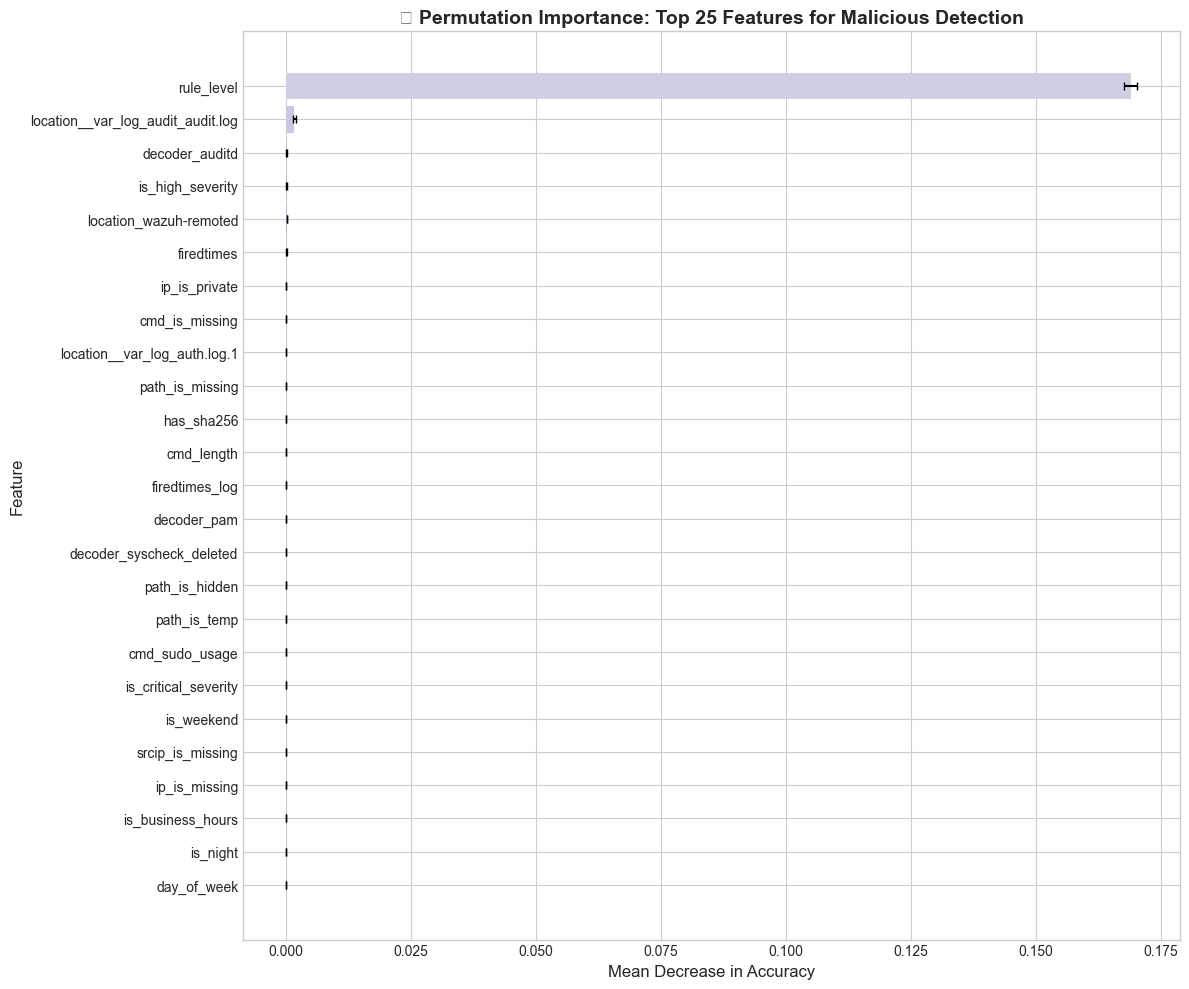

In [35]:
# Permutation Importance using Random Forest
print("🔀 Computing Permutation Importance (this may take a while)...")

perm_importance = permutation_importance(
    rf_malicious, X_test_mal, y_test_mal,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_importance_mal = pd.DataFrame({
    'Feature': X_no_mitre.columns,
    'Importance_Mean': perm_importance.importances_mean,
    'Importance_Std': perm_importance.importances_std
}).sort_values('Importance_Mean', ascending=False)

print(f"\n✅ Permutation Importance computed!")
print(f"\n📊 Top 20 Features by Permutation Importance (Malicious Detection):")
print("="*70)
print(perm_importance_mal.head(20).to_string(index=False))

# Visualize with error bars
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
top_perm = perm_importance_mal.head(top_n)
ax.barh(range(top_n), top_perm['Importance_Mean'], xerr=top_perm['Importance_Std'], 
        color=plt.cm.Purples(np.linspace(0.3, 0.9, top_n)), capsize=3)
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_perm['Feature'])
ax.invert_yaxis()
ax.set_title(f'🔀 Permutation Importance: Top {top_n} Features for Malicious Detection', fontsize=14, fontweight='bold')
ax.set_xlabel('Mean Decrease in Accuracy', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 🎨 A.6 SHAP Values Analysis (Explainability)

🎨 Computing SHAP values for Malicious Detection...
✅ SHAP values computed for 2000 samples!


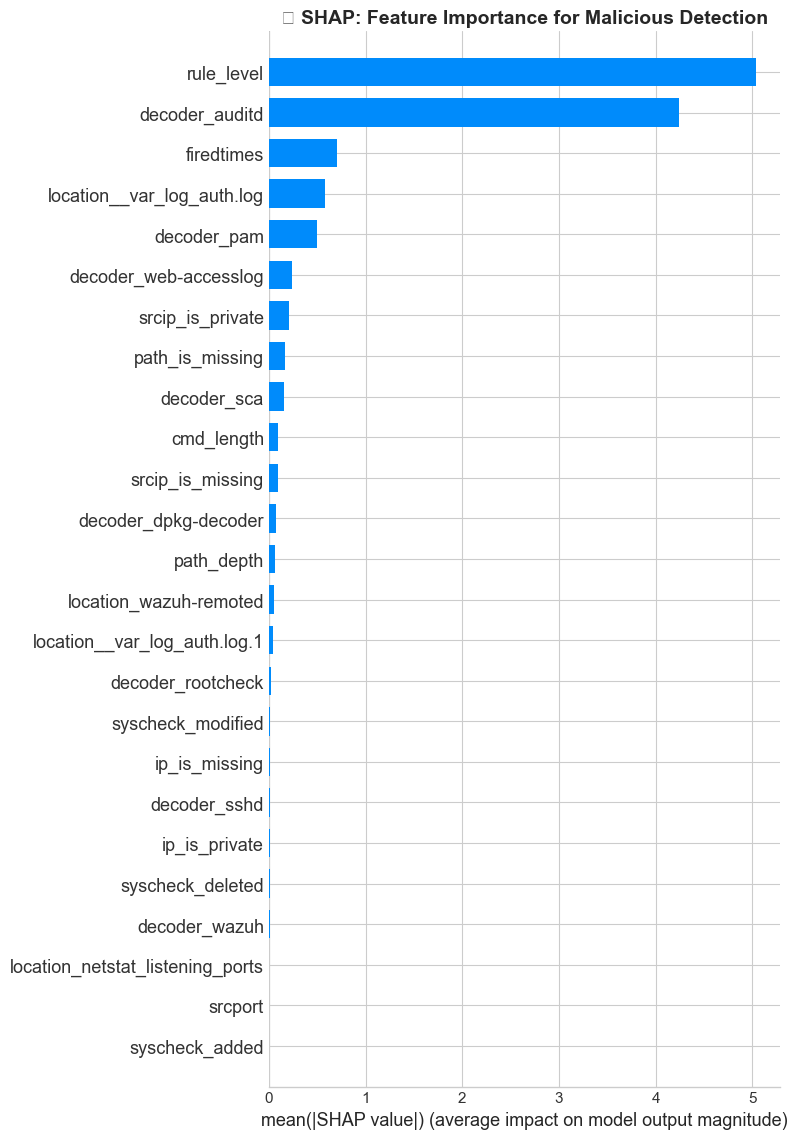

In [36]:
# SHAP Analysis for XGBoost model (Malicious detection)
print("🎨 Computing SHAP values for Malicious Detection...")

# Use a sample if dataset is large
sample_size = min(2000, len(X_test_mal))
X_sample = X_test_mal.sample(n=sample_size, random_state=42)

# Create SHAP explainer for XGBoost
explainer_mal = shap.TreeExplainer(xgb_malicious)
shap_values_mal = explainer_mal.shap_values(X_sample)

print(f"✅ SHAP values computed for {sample_size} samples!")

# SHAP Summary Plot - Bar
fig, ax = plt.subplots(figsize=(12, 10))
shap.summary_plot(shap_values_mal, X_sample, plot_type="bar", max_display=25, show=False)
plt.title("🎨 SHAP: Feature Importance for Malicious Detection", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

🐝 SHAP Beeswarm Plot - Shows HOW features affect predictions:


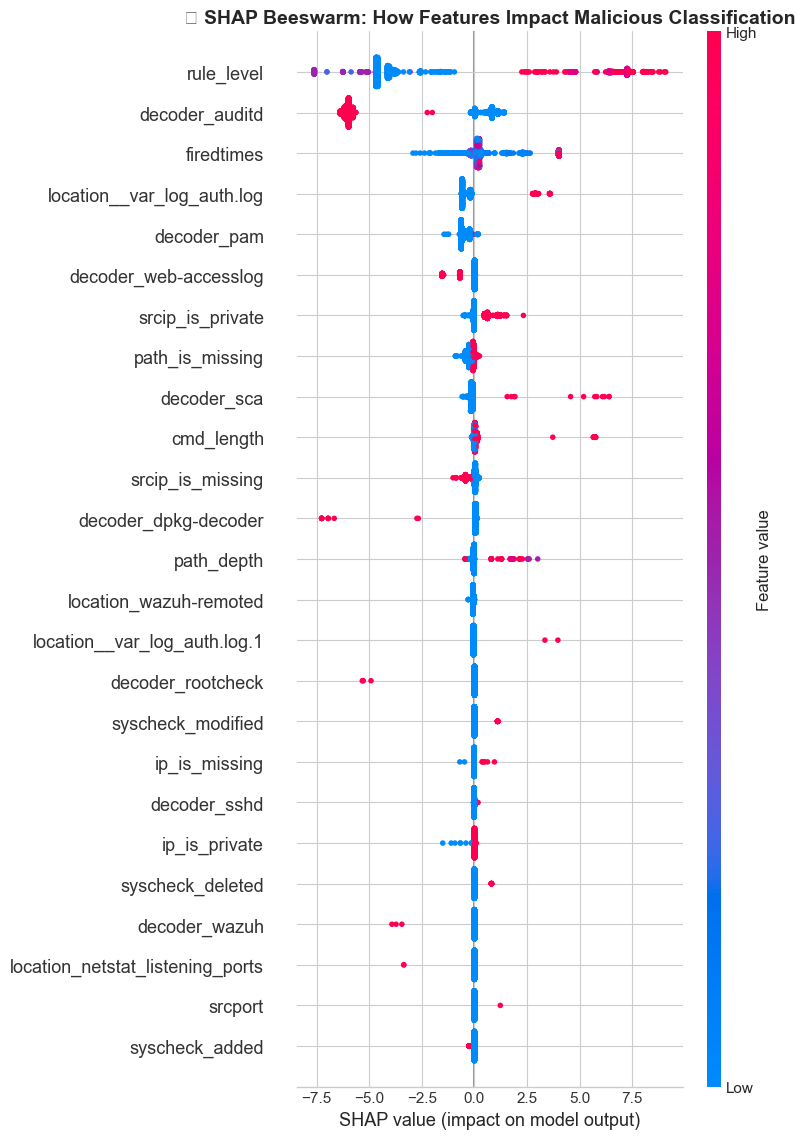


📖 Interpretation:
   - RED dots = HIGH feature values
   - BLUE dots = LOW feature values
   - Position RIGHT of center = Pushes toward MALICIOUS (1)
   - Position LEFT of center = Pushes toward BENIGN (0)


In [37]:
# SHAP Summary Plot - Beeswarm (shows feature value impact direction)
print("🐝 SHAP Beeswarm Plot - Shows HOW features affect predictions:")
fig, ax = plt.subplots(figsize=(14, 12))
shap.summary_plot(shap_values_mal, X_sample, max_display=25, show=False)
plt.title("🎨 SHAP Beeswarm: How Features Impact Malicious Classification", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📖 Interpretation:")
print("   - RED dots = HIGH feature values")
print("   - BLUE dots = LOW feature values")
print("   - Position RIGHT of center = Pushes toward MALICIOUS (1)")
print("   - Position LEFT of center = Pushes toward BENIGN (0)")

### 📈 A.7 Statistical Feature Selection (Filter Methods)

📈 Computing Mutual Information Scores...

📊 Top 20 Features by Mutual Information (Malicious Detection):
                             Feature  MI_Score
                          rule_level  0.379541
                      decoder_auditd  0.319701
   location__var_log_audit_audit.log  0.319400
                    srcip_is_private  0.193659
location__var_log_apache2_access.log  0.177575
               decoder_web-accesslog  0.177137
                          cmd_length  0.121543
                          has_sha256  0.120599
                             has_md5  0.120160
                     path_is_missing  0.107799
                      cmd_is_missing  0.095916
                    is_high_severity  0.033825
                   syscheck_modified  0.021505
  decoder_syscheck_integrity_changed  0.021197
                          path_depth  0.019803
                   location_syscheck  0.018022
                   path_is_sensitive  0.017113
                         changed_md5  0.016689
  

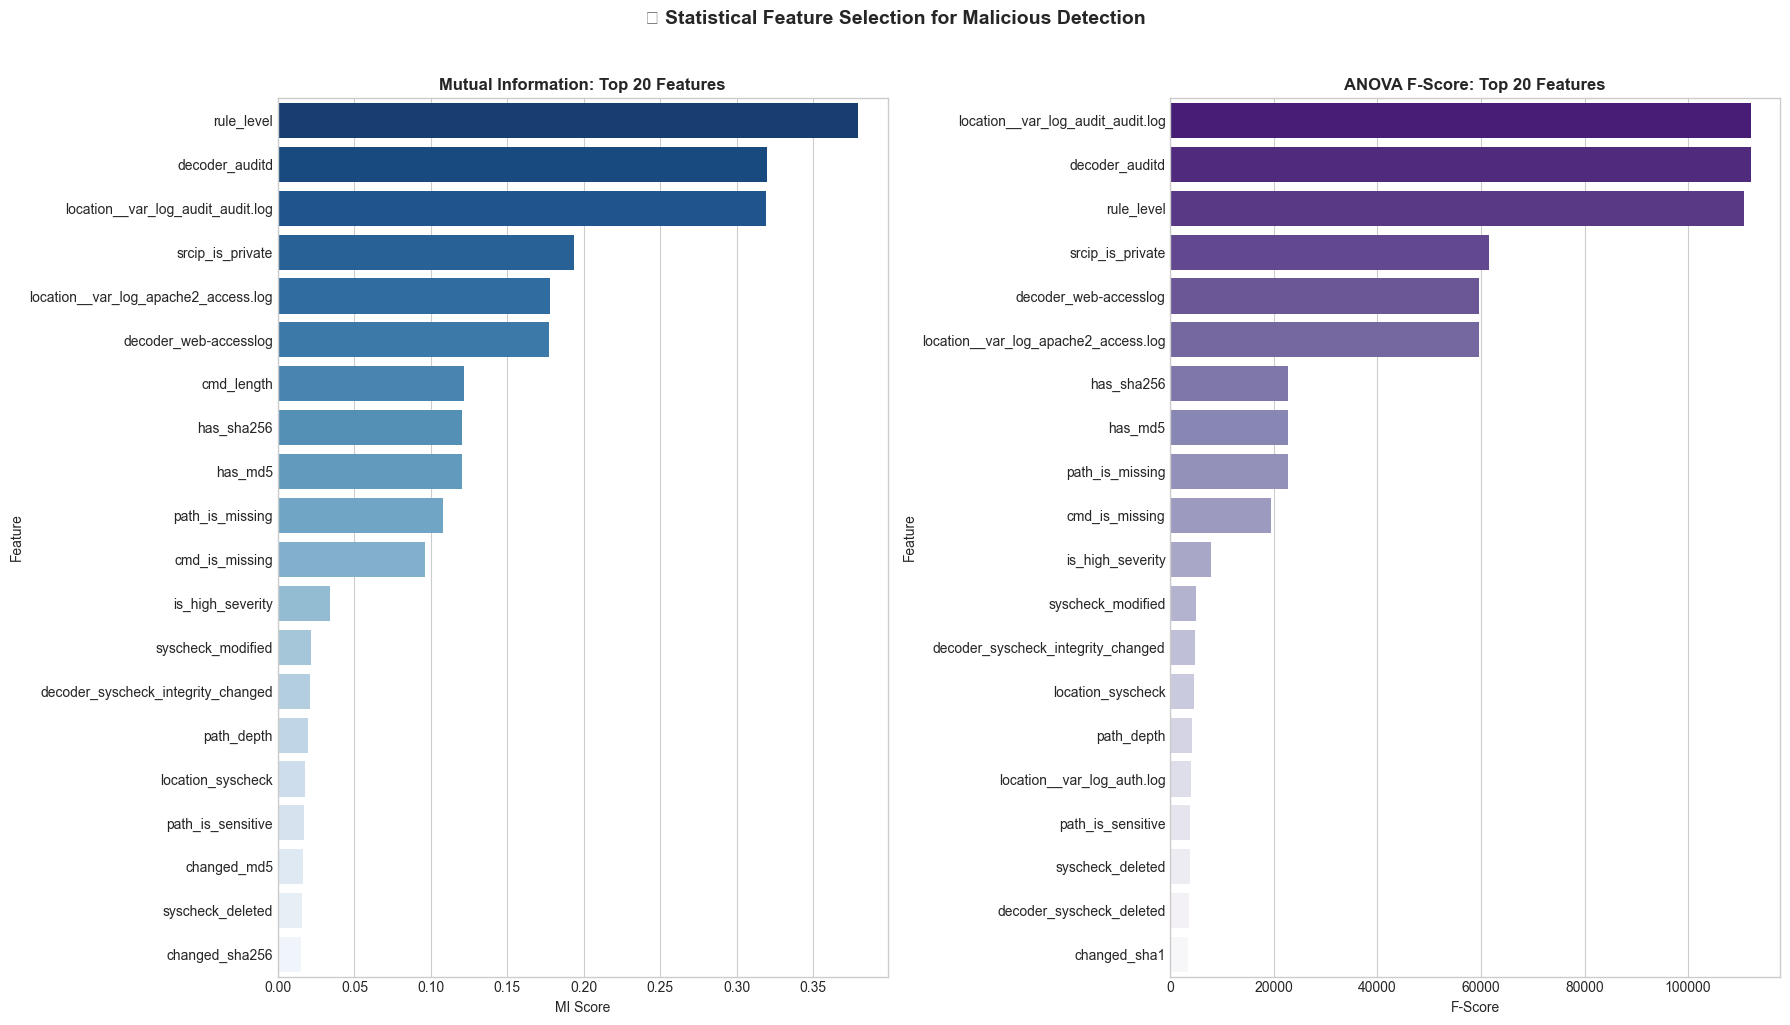

In [38]:
# Mutual Information - measures dependency between features and target
print("📈 Computing Mutual Information Scores...")

mi_scores = mutual_info_classif(X_train_mal, y_train_mal, random_state=42)
mi_importance_mal = pd.DataFrame({
    'Feature': X_no_mitre.columns,
    'MI_Score': mi_scores
}).sort_values('MI_Score', ascending=False)

print(f"\n📊 Top 20 Features by Mutual Information (Malicious Detection):")
print("="*70)
print(mi_importance_mal.head(20).to_string(index=False))

# F-statistic (ANOVA)
print("\n📈 Computing F-statistic (ANOVA) Scores...")
f_scores, p_values = f_classif(X_train_mal, y_train_mal)
f_importance_mal = pd.DataFrame({
    'Feature': X_no_mitre.columns,
    'F_Score': f_scores,
    'P_Value': p_values
}).sort_values('F_Score', ascending=False)

print(f"\n📊 Top 20 Features by F-Score (Malicious Detection):")
print("="*70)
print(f_importance_mal.head(20).to_string(index=False))

# Visualize both
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Mutual Information
top_n = 20
sns.barplot(data=mi_importance_mal.head(top_n), y='Feature', x='MI_Score', 
            palette='Blues_r', ax=axes[0])
axes[0].set_title(f'Mutual Information: Top {top_n} Features', fontsize=12, fontweight='bold')
axes[0].set_xlabel('MI Score')

# F-Score
sns.barplot(data=f_importance_mal.head(top_n), y='Feature', x='F_Score', 
            palette='Purples_r', ax=axes[1])
axes[1].set_title(f'ANOVA F-Score: Top {top_n} Features', fontsize=12, fontweight='bold')
axes[1].set_xlabel('F-Score')

plt.suptitle('📈 Statistical Feature Selection for Malicious Detection', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 📊 A.8 Combined Feature Ranking (Consensus)

📊 Creating Combined Feature Ranking for MALICIOUS Detection...

🏆 TOP 30 FEATURES FOR MALICIOUS DETECTION (Consensus Ranking)
                             Feature       RF      XGB      LGB     Perm       MI  F_Score  Average_Score  Average_Rank
                          rule_level 1.000000 0.503689 0.436059 1.000000 1.000000      NaN       0.787950           1.4
                      decoder_auditd 0.541271 0.217294 0.039405 0.001789 0.842334      NaN       0.328419           4.6
   location__var_log_audit_audit.log 0.598763 0.000000 0.000000 0.010681 0.841541      NaN       0.290197          26.4
          location__var_log_auth.log 0.088463 1.000000 0.040520 0.000000 0.036473      NaN       0.233091          27.0
                          firedtimes 0.048134 0.001564 1.000000 0.001303 0.000000      NaN       0.210200          22.5
                    srcip_is_private 0.295681 0.002129 0.043494 0.000613 0.510244      NaN       0.170432          21.0
               decoder_web-accessl

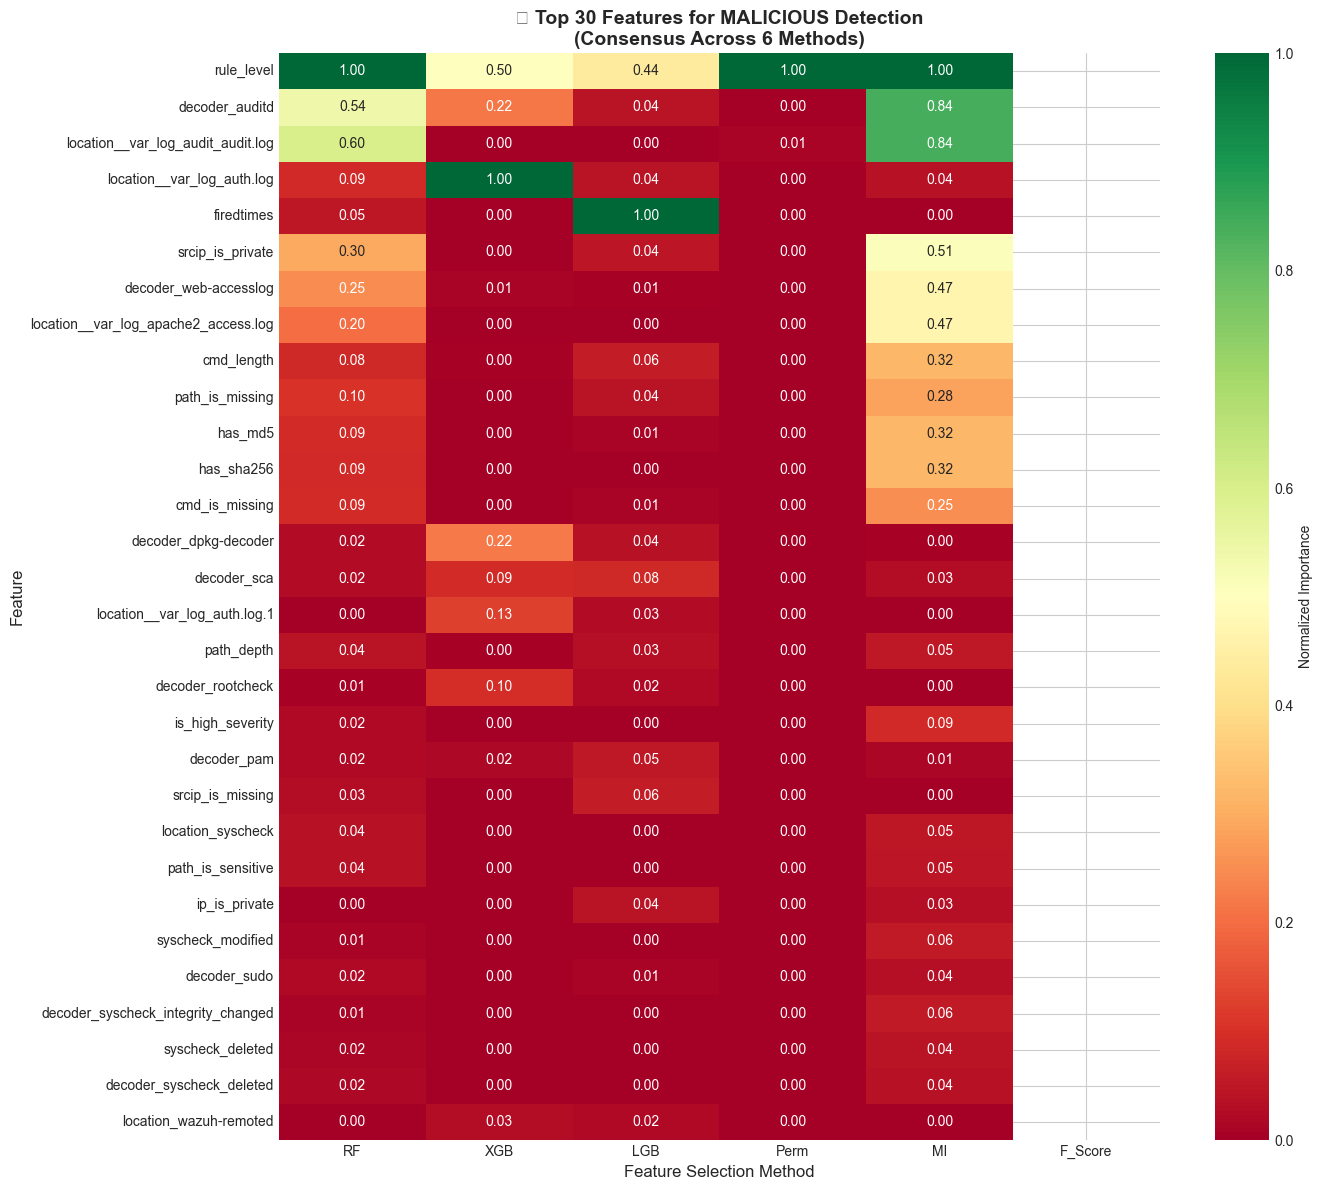

In [39]:
# Combine all importance rankings for consensus
print("📊 Creating Combined Feature Ranking for MALICIOUS Detection...")

# Normalize all importance scores to [0, 1]
def normalize(series):
    return (series - series.min()) / (series.max() - series.min() + 1e-10)

# Create combined dataframe (using X_no_mitre - MITRE features masked)
combined_mal = pd.DataFrame({'Feature': X_no_mitre.columns})

# Add normalized scores from each method
combined_mal['RF'] = normalize(rf_importance_mal.set_index('Feature').loc[X_no_mitre.columns, 'Importance'].values)
combined_mal['XGB'] = normalize(xgb_importance_mal.set_index('Feature').loc[X_no_mitre.columns, 'Importance'].values)
combined_mal['LGB'] = normalize(lgb_importance_mal.set_index('Feature').loc[X_no_mitre.columns, 'Importance'].values)
combined_mal['Perm'] = normalize(perm_importance_mal.set_index('Feature').loc[X_no_mitre.columns, 'Importance_Mean'].values)
combined_mal['MI'] = normalize(mi_importance_mal.set_index('Feature').loc[X_no_mitre.columns, 'MI_Score'].values)
combined_mal['F_Score'] = normalize(f_importance_mal.set_index('Feature').loc[X_no_mitre.columns, 'F_Score'].values)

# Calculate average score
combined_mal['Average_Score'] = combined_mal[['RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score']].mean(axis=1)

# Calculate rank for each method
for col in ['RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score']:
    combined_mal[f'{col}_Rank'] = combined_mal[col].rank(ascending=False)

combined_mal['Average_Rank'] = combined_mal[[f'{col}_Rank' for col in ['RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score']]].mean(axis=1)

# Sort by average score
combined_mal = combined_mal.sort_values('Average_Score', ascending=False)

print("\n" + "="*100)
print("🏆 TOP 30 FEATURES FOR MALICIOUS DETECTION (Consensus Ranking)")
print("="*100)
display_cols = ['Feature', 'RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score', 'Average_Score', 'Average_Rank']
print(combined_mal[display_cols].head(30).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(14, 12))
top_n = 30
top_features = combined_mal.head(top_n)

# Create heatmap data
heatmap_data = top_features.set_index('Feature')[['RF', 'XGB', 'LGB', 'Perm', 'MI', 'F_Score']]
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax, 
            cbar_kws={'label': 'Normalized Importance'})
ax.set_title('🏆 Top 30 Features for MALICIOUS Detection\n(Consensus Across 6 Methods)', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Selection Method', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### ✅ Summary: Malicious Detection Results (NO DATA LEAKAGE)

In [40]:
# ============================================================================
# 📊 SUMMARY: MALICIOUS DETECTION RESULTS (DATA LEAKAGE FIXED)
# ============================================================================

print("="*80)
print("📊 MALICIOUS DETECTION RESULTS - DATA LEAKAGE FIXED!")
print("="*80)

print(f"\n🛡️ MITRE Features MASKED: {len(mitre_columns)} features removed")
print(f"   Features used: {X_no_mitre.shape[1]} (vs {X.shape[1]} original)")

print(f"\n📈 MODEL ACCURACIES (REAL - NO DATA LEAKAGE):")
print("-"*50)
print(f"   🌲 Random Forest:  {rf_accuracy*100:.2f}%")
print(f"   🚀 XGBoost:        {xgb_accuracy*100:.2f}%")
print(f"   💡 LightGBM:       {lgb_accuracy*100:.2f}%")

print(f"\n🏆 TOP 10 MOST IMPORTANT FEATURES (Consensus):")
print("-"*50)
top_10_features = combined_mal.head(10)[['Feature', 'Average_Score']].values
for i, (feat, score) in enumerate(top_10_features, 1):
    print(f"   {i:2d}. {feat:40s} (score: {score:.3f})")

print("\n" + "="*80)
print("✅ These results are RELIABLE - no data leakage from MITRE features!")
print("="*80)

📊 MALICIOUS DETECTION RESULTS - DATA LEAKAGE FIXED!

🛡️ MITRE Features MASKED: 17 features removed
   Features used: 90 (vs 107 original)

📈 MODEL ACCURACIES (REAL - NO DATA LEAKAGE):
--------------------------------------------------
   🌲 Random Forest:  98.68%
   🚀 XGBoost:        98.71%
   💡 LightGBM:       98.71%

🏆 TOP 10 MOST IMPORTANT FEATURES (Consensus):
--------------------------------------------------
    1. rule_level                               (score: 0.788)
    2. decoder_auditd                           (score: 0.328)
    3. location__var_log_audit_audit.log        (score: 0.290)
    4. location__var_log_auth.log               (score: 0.233)
    5. firedtimes                               (score: 0.210)
    6. srcip_is_private                         (score: 0.170)
    7. decoder_web-accesslog                    (score: 0.146)
    8. location__var_log_apache2_access.log     (score: 0.134)
    9. cmd_length                               (score: 0.094)
   10. path_is_m

---
# 🔗 PART B: Feature Importance for CYBER KILL CHAIN Stage Classification

## Which features determine the STAGE of an attack in the Cyber Kill Chain?

The Cyber Kill Chain stages typically include:
1. **Reconnaissance** - Gathering information about the target
2. **Weaponization** - Creating attack tools
3. **Delivery** - Transmitting the attack
4. **Exploitation** - Executing malicious code
5. **Installation** - Installing malware
6. **Command & Control (C2)** - Remote communication
7. **Actions on Objectives** - Achieving attacker goals

### 📊 B.1 Prepare Data for CKC Classification (Malicious samples only)

In [14]:
# For CKC stage prediction, we focus on MALICIOUS samples only
# (benign samples don't have a meaningful CKC stage)

print("📊 Preparing Data for Cyber Kill Chain Stage Classification...")
print("="*70)

# Filter to malicious samples with valid CKC labels
malicious_mask = df['malicious'] == 1
ckc_valid_mask = df['cyber_kill_chain_tactic'].notna() & (df['cyber_kill_chain_tactic'] != 'Unknown')

# Combine masks
valid_ckc_mask = malicious_mask & ckc_valid_mask

X_ckc = X[valid_ckc_mask].copy()
y_ckc_filtered = df.loc[valid_ckc_mask, 'cyber_kill_chain_tactic'].values

print(f"✅ Total malicious samples: {malicious_mask.sum():,}")
print(f"✅ Samples with valid CKC stage: {valid_ckc_mask.sum():,}")

# Show CKC distribution
print(f"\n📊 Cyber Kill Chain Stage Distribution:")
print("-"*50)
ckc_dist = pd.Series(y_ckc_filtered).value_counts()
for stage, count in ckc_dist.items():
    print(f"   {stage}: {count:,} samples ({count/len(y_ckc_filtered)*100:.1f}%)")

# Encode CKC labels
ckc_label_encoder = LabelEncoder()
y_ckc_encoded_filtered = ckc_label_encoder.fit_transform(y_ckc_filtered)

print(f"\n🏷️ CKC Classes ({len(ckc_label_encoder.classes_)} total):")
for i, cls in enumerate(ckc_label_encoder.classes_):
    print(f"   {i}: {cls}")

📊 Preparing Data for Cyber Kill Chain Stage Classification...
✅ Total malicious samples: 25,418
✅ Samples with valid CKC stage: 24,548

📊 Cyber Kill Chain Stage Distribution:
--------------------------------------------------
   S3: 16,556 samples (67.4%)
   S4: 4,291 samples (17.5%)
   S7: 1,777 samples (7.2%)
   S5: 1,281 samples (5.2%)
   S1: 643 samples (2.6%)

🏷️ CKC Classes (5 total):
   0: S1
   1: S3
   2: S4
   3: S5
   4: S7


In [15]:
# Train/Test split for CKC classification
X_train_ckc, X_test_ckc, y_train_ckc, y_test_ckc = train_test_split(
    X_ckc, y_ckc_encoded_filtered, test_size=0.2, random_state=42, stratify=y_ckc_encoded_filtered
)

print("📊 Data Split for CKC Stage Classification:")
print(f"   Training set: {X_train_ckc.shape[0]:,} samples")
print(f"   Test set: {X_test_ckc.shape[0]:,} samples")

# Show distribution in train/test
print("\n📊 Training Set Distribution:")
for i, cls in enumerate(ckc_label_encoder.classes_):
    count = (y_train_ckc == i).sum()
    print(f"   {cls}: {count} samples")

print("\n📊 Test Set Distribution:")
for i, cls in enumerate(ckc_label_encoder.classes_):
    count = (y_test_ckc == i).sum()
    print(f"   {cls}: {count} samples")

📊 Data Split for CKC Stage Classification:
   Training set: 19,638 samples
   Test set: 4,910 samples

📊 Training Set Distribution:
   S1: 514 samples
   S3: 13244 samples
   S4: 3433 samples
   S5: 1025 samples
   S7: 1422 samples

📊 Test Set Distribution:
   S1: 129 samples
   S3: 3312 samples
   S4: 858 samples
   S5: 256 samples
   S7: 355 samples


### 🌲 B.2 Random Forest Feature Importance for CKC Stages

🌲 Training Random Forest for CKC Stage Classification...

✅ Random Forest trained!
   Test Accuracy: 84.07%

📊 Top 20 Features for CKC STAGE Detection (Random Forest):
                           Feature  Importance
                        firedtimes    0.091193
                    firedtimes_log    0.085480
                        rule_level    0.078524
                  is_high_severity    0.078126
                  syscheck_deleted    0.074585
                 syscheck_modified    0.057351
          decoder_syscheck_deleted    0.049720
                   path_is_missing    0.043038
                           has_md5    0.037465
decoder_syscheck_integrity_changed    0.034618
                        has_sha256    0.031981
                 location_syscheck    0.030870
                        path_depth    0.027772
                       changed_md5    0.023223
                      changed_sha1    0.022315
                 path_is_sensitive    0.022156
                  srcip_is_privat

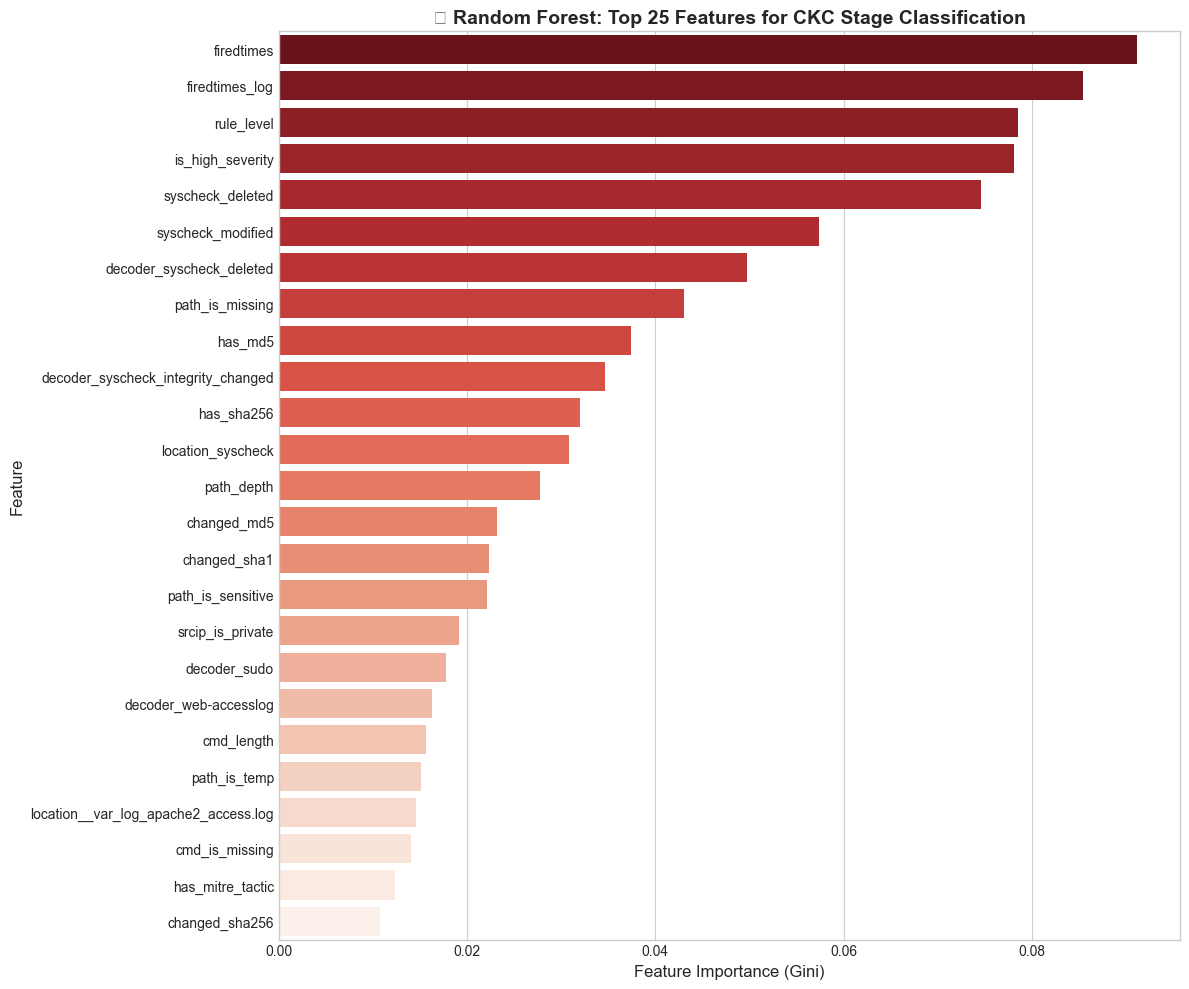


📊 Classification Report for CKC Stages:
----------------------------------------------------------------------
              precision    recall  f1-score   support

          S1       0.38      0.81      0.52       129
          S3       0.99      0.83      0.90      3312
          S4       0.53      0.77      0.63       858
          S5       1.00      1.00      1.00       256
          S7       1.00      1.00      1.00       355

    accuracy                           0.84      4910
   macro avg       0.78      0.88      0.81      4910
weighted avg       0.89      0.84      0.86      4910



In [16]:
# Train Random Forest for CKC Stage classification (Multi-class)
print("🌲 Training Random Forest for CKC Stage Classification...")

rf_ckc = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

rf_ckc.fit(X_train_ckc, y_train_ckc)

# Get feature importances
rf_importance_ckc = pd.DataFrame({
    'Feature': X_ckc.columns,
    'Importance': rf_ckc.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_rf_ckc = rf_ckc.predict(X_test_ckc)
rf_accuracy_ckc = accuracy_score(y_test_ckc, y_pred_rf_ckc)

print(f"\n✅ Random Forest trained!")
print(f"   Test Accuracy: {rf_accuracy_ckc*100:.2f}%")
print(f"\n📊 Top 20 Features for CKC STAGE Detection (Random Forest):")
print("="*70)
print(rf_importance_ckc.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=rf_importance_ckc.head(top_n), y='Feature', x='Importance', palette='Reds_r', ax=ax)
ax.set_title(f'🌲 Random Forest: Top {top_n} Features for CKC Stage Classification', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Gini)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

# Show classification report
print("\n📊 Classification Report for CKC Stages:")
print("-"*70)
print(classification_report(y_test_ckc, y_pred_rf_ckc, 
                            target_names=ckc_label_encoder.classes_))

### 🚀 B.3 XGBoost Feature Importance for CKC Stages

🚀 Training XGBoost for CKC Stage Classification...

✅ XGBoost trained!
   Test Accuracy: 90.22%

📊 Top 20 Features for CKC STAGE Detection (XGBoost):
                     Feature  Importance
           syscheck_modified    0.440722
            syscheck_deleted    0.274788
                  cmd_length    0.077794
                  path_depth    0.058551
              decoder_auditd    0.045663
                  rule_level    0.028687
      location_wazuh-remoted    0.014028
       decoder_web-accesslog    0.013553
             path_is_missing    0.009898
  location__var_log_auth.log    0.009177
                 decoder_pam    0.008678
               decoder_ossec    0.007463
       location_logcollector    0.003440
                  firedtimes    0.003220
            srcip_is_private    0.002499
                path_is_temp    0.000783
location__var_log_auth.log.1    0.000446
                decoder_sshd    0.000281
            has_mitre_tactic    0.000160
           path_is_sensitive  

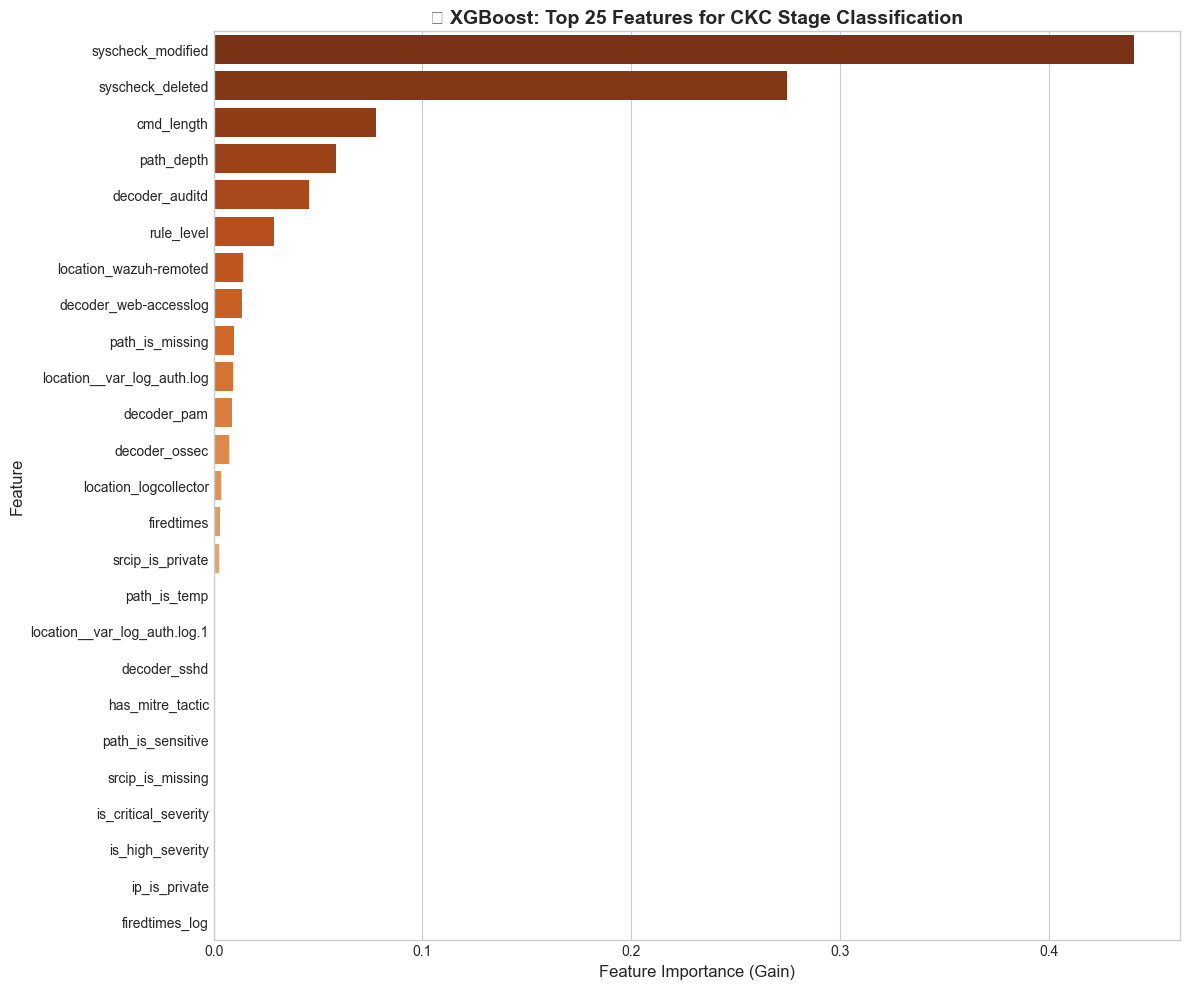

In [17]:
# Train XGBoost for CKC Stage classification (Multi-class)
print("🚀 Training XGBoost for CKC Stage Classification...")

xgb_ckc = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    objective='multi:softmax'
)

xgb_ckc.fit(X_train_ckc, y_train_ckc)

# Get feature importances
xgb_importance_ckc = pd.DataFrame({
    'Feature': X_ckc.columns,
    'Importance': xgb_ckc.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_xgb_ckc = xgb_ckc.predict(X_test_ckc)
xgb_accuracy_ckc = accuracy_score(y_test_ckc, y_pred_xgb_ckc)

print(f"\n✅ XGBoost trained!")
print(f"   Test Accuracy: {xgb_accuracy_ckc*100:.2f}%")
print(f"\n📊 Top 20 Features for CKC STAGE Detection (XGBoost):")
print("="*70)
print(xgb_importance_ckc.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=xgb_importance_ckc.head(top_n), y='Feature', x='Importance', palette='Oranges_r', ax=ax)
ax.set_title(f'🚀 XGBoost: Top {top_n} Features for CKC Stage Classification', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Gain)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 💡 B.4 LightGBM Feature Importance for CKC Stages

💡 Training LightGBM for CKC Stage Classification...

✅ LightGBM trained!
   Test Accuracy: 84.30%

📊 Top 20 Features for CKC STAGE Detection (LightGBM):
                     Feature  Importance
                  firedtimes       19409
                  rule_level        3062
            srcip_is_private         456
       decoder_web-accesslog         287
  location__var_log_auth.log         278
                  cmd_length         276
location__var_log_auth.log.1         274
                 decoder_pam         238
            syscheck_deleted         179
            has_mitre_tactic         173
             path_is_missing         169
              decoder_auditd         139
                     srcport         122
                  path_depth         115
               decoder_ossec         107
                decoder_sshd          96
           syscheck_modified          80
            srcip_is_missing          68
      location_wazuh-remoted          59
              cmd_is_missin

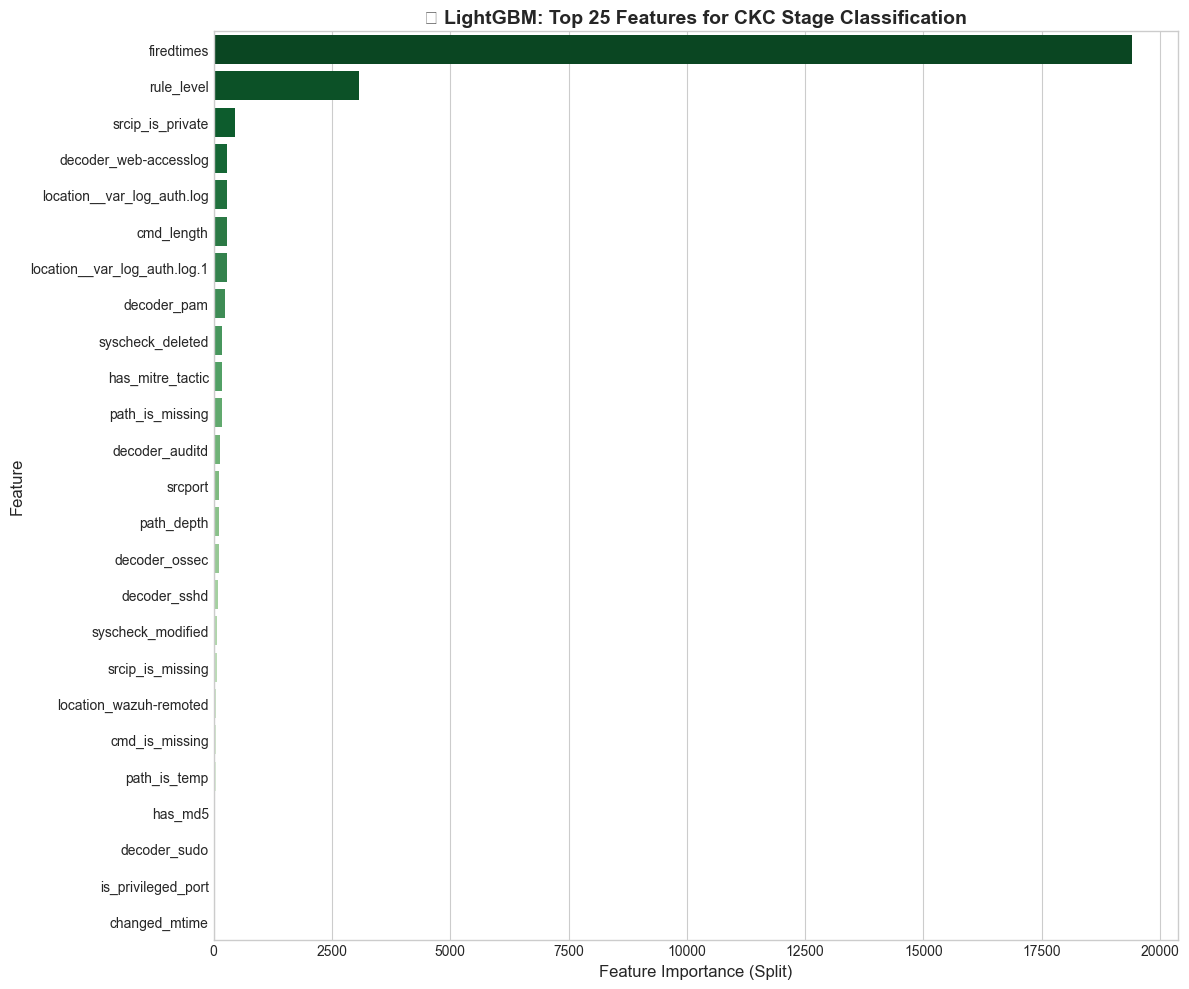

In [18]:
# Train LightGBM for CKC Stage classification
print("💡 Training LightGBM for CKC Stage Classification...")

lgb_ckc = lgb.LGBMClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1,
    objective='multiclass'
)

lgb_ckc.fit(X_train_ckc, y_train_ckc)

# Get feature importances
lgb_importance_ckc = pd.DataFrame({
    'Feature': X_ckc.columns,
    'Importance': lgb_ckc.feature_importances_
}).sort_values('Importance', ascending=False)

# Evaluate
y_pred_lgb_ckc = lgb_ckc.predict(X_test_ckc)
lgb_accuracy_ckc = accuracy_score(y_test_ckc, y_pred_lgb_ckc)

print(f"\n✅ LightGBM trained!")
print(f"   Test Accuracy: {lgb_accuracy_ckc*100:.2f}%")
print(f"\n📊 Top 20 Features for CKC STAGE Detection (LightGBM):")
print("="*70)
print(lgb_importance_ckc.head(20).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
sns.barplot(data=lgb_importance_ckc.head(top_n), y='Feature', x='Importance', palette='Greens_r', ax=ax)
ax.set_title(f'💡 LightGBM: Top {top_n} Features for CKC Stage Classification', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance (Split)', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### 🎨 B.5 SHAP Analysis for CKC Stages (Per-Class Feature Impact)

🎨 Computing SHAP values for CKC Stage Classification...
   (This shows which features are important for EACH CKC stage)
✅ SHAP values computed for 1500 samples!


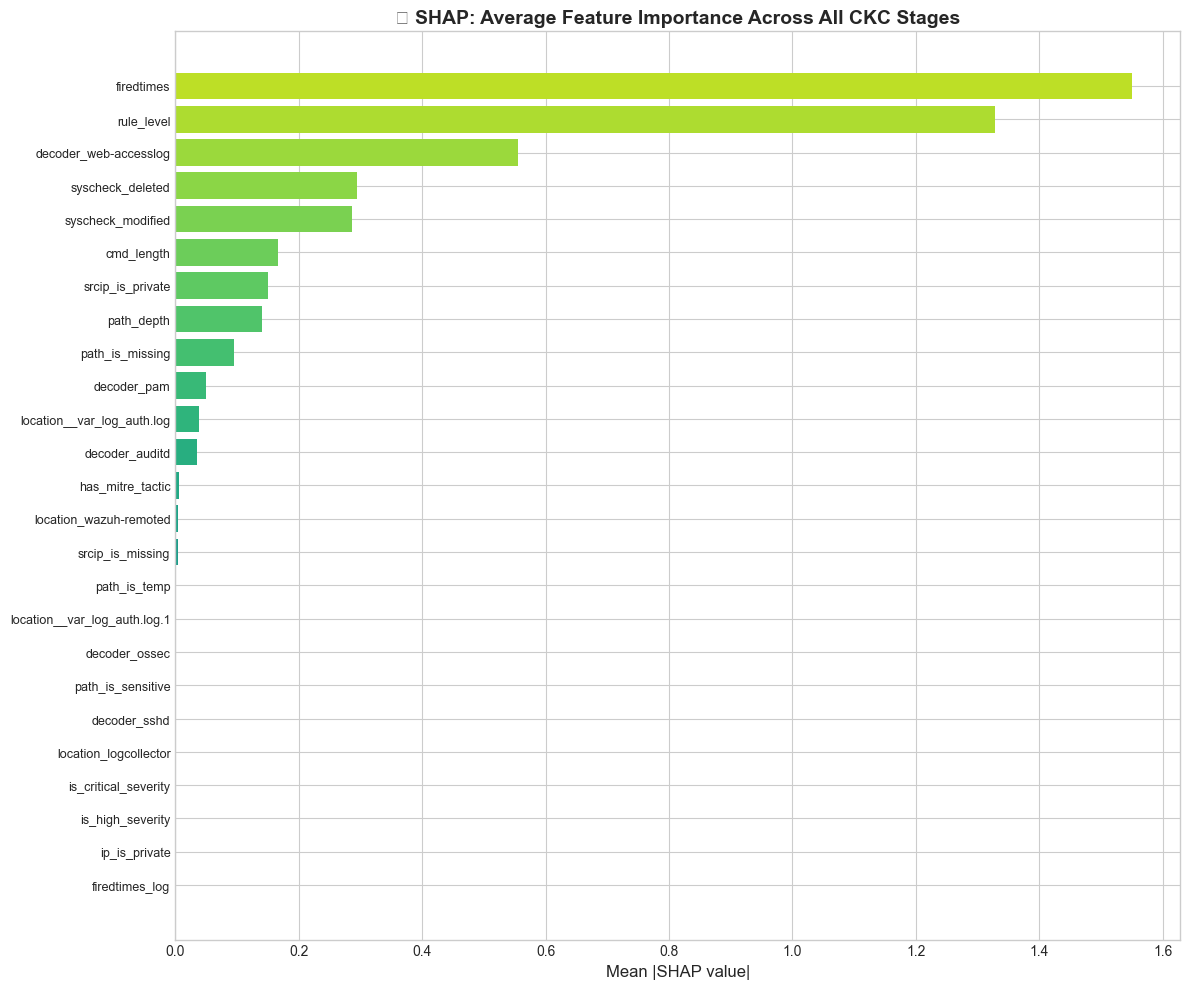


📊 Top 20 Features by SHAP (CKC Stages):
                     Feature  SHAP_Importance
                  firedtimes         1.550715
                  rule_level         1.328324
       decoder_web-accesslog         0.554973
            syscheck_deleted         0.294881
           syscheck_modified         0.286057
                  cmd_length         0.165818
            srcip_is_private         0.150797
                  path_depth         0.140762
             path_is_missing         0.094877
                 decoder_pam         0.049148
  location__var_log_auth.log         0.038415
              decoder_auditd         0.035223
            has_mitre_tactic         0.006116
      location_wazuh-remoted         0.005046
            srcip_is_missing         0.005004
                path_is_temp         0.001459
location__var_log_auth.log.1         0.001297
               decoder_ossec         0.001127
           path_is_sensitive         0.000988
                decoder_sshd         0.

In [20]:
# SHAP Analysis for CKC Stage Classification
print("🎨 Computing SHAP values for CKC Stage Classification...")
print("   (This shows which features are important for EACH CKC stage)")

# Sample data if too large
sample_size = min(1500, len(X_test_ckc))
X_sample_ckc = X_test_ckc.sample(n=sample_size, random_state=42)

# Create SHAP explainer
explainer_ckc = shap.TreeExplainer(xgb_ckc)
shap_values_ckc = explainer_ckc.shap_values(X_sample_ckc)

print(f"✅ SHAP values computed for {sample_size} samples!")

# For multi-class XGBoost, shap_values is (n_samples, n_features, n_classes) or list of arrays
# We need to compute mean absolute SHAP across all classes and samples
if isinstance(shap_values_ckc, list):
    # List of arrays (one per class)
    shap_abs_mean = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values_ckc], axis=0)
else:
    # 3D array (samples, features, classes)
    shap_abs_mean = np.abs(shap_values_ckc).mean(axis=(0, 2)) if shap_values_ckc.ndim == 3 else np.abs(shap_values_ckc).mean(axis=0)

# Create importance dataframe
shap_importance_ckc = pd.DataFrame({
    'Feature': X_sample_ckc.columns,
    'SHAP_Importance': shap_abs_mean
}).sort_values('SHAP_Importance', ascending=False)

# Plot using matplotlib instead of shap's built-in
fig, ax = plt.subplots(figsize=(12, 10))
top_n = 25
top_shap = shap_importance_ckc.head(top_n)
ax.barh(range(top_n), top_shap['SHAP_Importance'].values[::-1], color=plt.cm.viridis(np.linspace(0.3, 0.9, top_n)))
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_shap['Feature'].values[::-1], fontsize=9)
ax.set_xlabel('Mean |SHAP value|', fontsize=12)
ax.set_title("🎨 SHAP: Average Feature Importance Across All CKC Stages", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n📊 Top 20 Features by SHAP (CKC Stages):")
print(shap_importance_ckc.head(20).to_string(index=False))

📊 Per-Class Feature Importance for each CKC Stage:

🔹 S1:
    Feature  SHAP_Importance
 rule_level         4.533586
 firedtimes         0.808426
hour_of_day         0.000000
 is_weekend         0.000000
day_of_week         0.000000

🔹 S3:
         Feature  SHAP_Importance
      firedtimes         2.189909
      rule_level         1.310002
      path_depth         0.521858
      cmd_length         0.399295
srcip_is_private         0.278641

🔹 S4:
              Feature  SHAP_Importance
           firedtimes         2.255652
decoder_web-accesslog         0.843775
           cmd_length         0.428372
           rule_level         0.426724
           path_depth         0.173625

🔹 S5:
         Feature  SHAP_Importance
      firedtimes         2.246390
syscheck_deleted         1.432855
srcip_is_private         0.329354
      rule_level         0.260993
 path_is_missing         0.029372

🔹 S7:
              Feature  SHAP_Importance
decoder_web-accesslog         1.813784
    syscheck_modifie

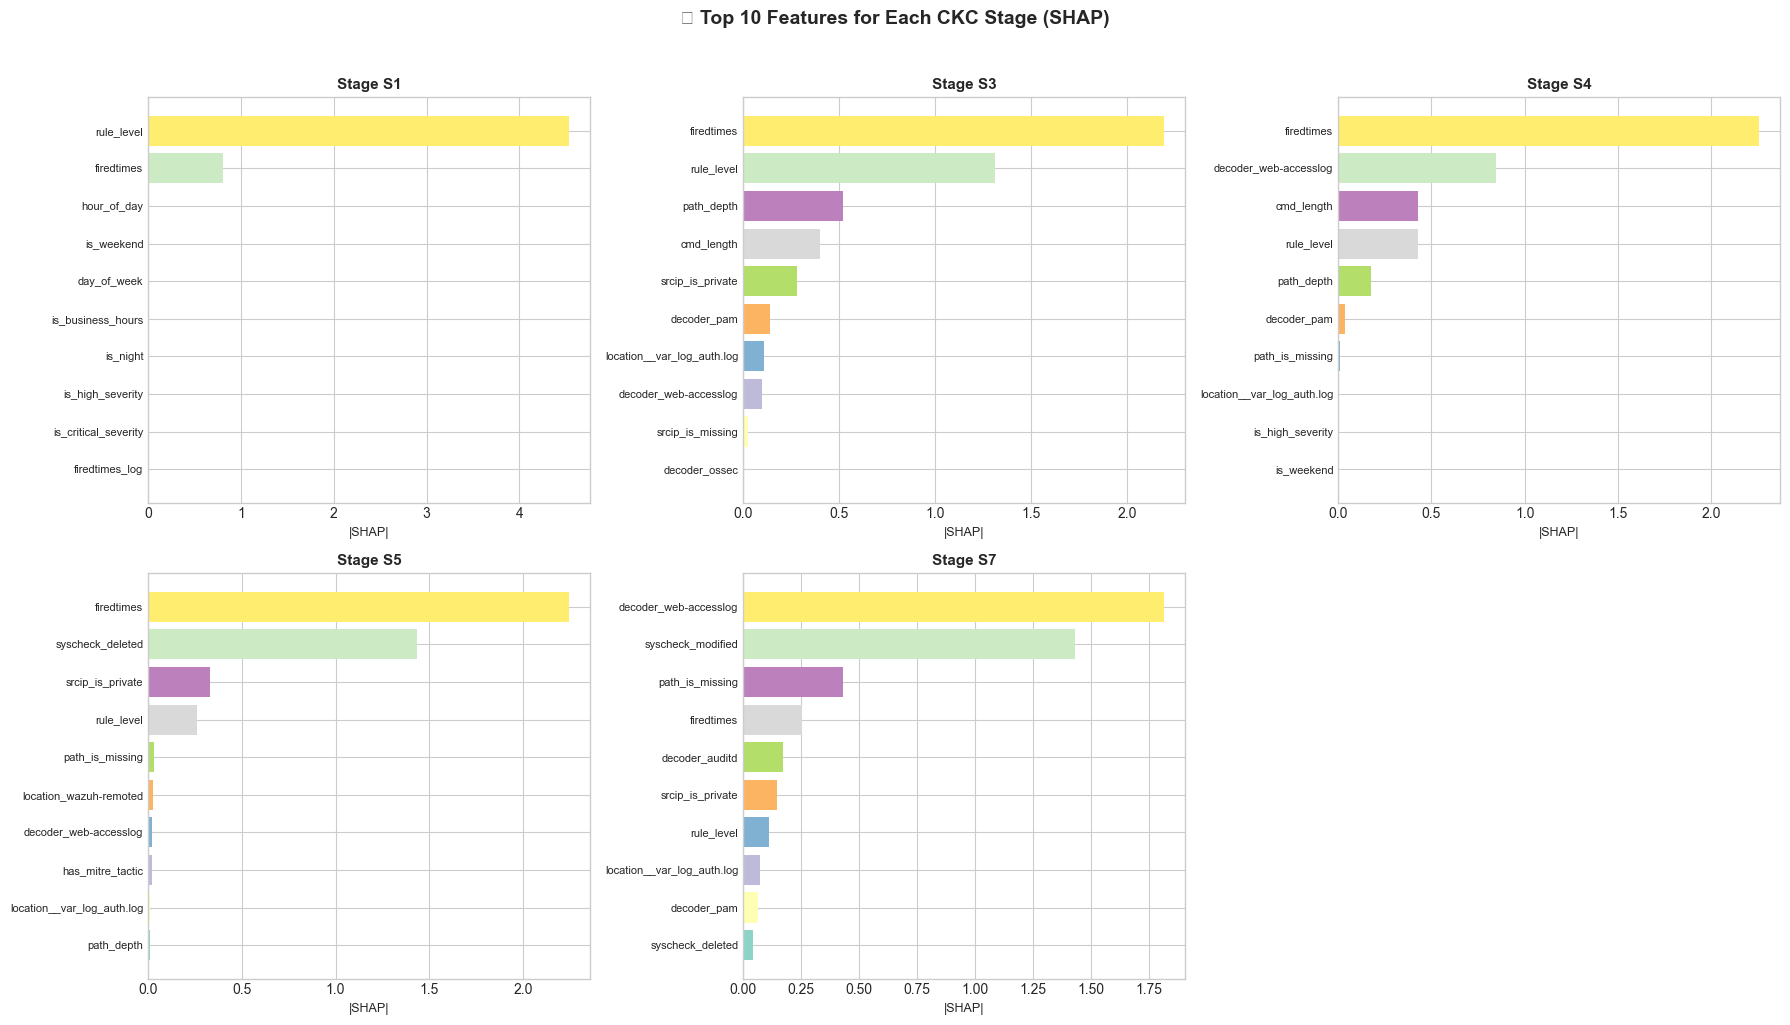

In [21]:
# Per-class SHAP analysis - show important features for each CKC stage
print("📊 Per-Class Feature Importance for each CKC Stage:")
print("="*70)

n_classes = len(ckc_label_encoder.classes_)

# Handle different SHAP value formats
if isinstance(shap_values_ckc, list):
    # List format - one array per class
    class_shap_arrays = shap_values_ckc
elif shap_values_ckc.ndim == 3:
    # 3D array (samples, features, classes)
    class_shap_arrays = [shap_values_ckc[:, :, i] for i in range(n_classes)]
else:
    # 2D array - use same values for each class
    class_shap_arrays = [shap_values_ckc for _ in range(n_classes)]

# Create subplots
n_cols = min(3, n_classes)
n_rows = (n_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
if n_classes == 1:
    axes = np.array([[axes]])
elif n_rows == 1:
    axes = axes.reshape(1, -1)

class_importance_dict = {}

for i, cls_name in enumerate(ckc_label_encoder.classes_):
    row, col = i // n_cols, i % n_cols
    ax = axes[row, col]
    
    # Get mean absolute SHAP values for this class
    if i < len(class_shap_arrays):
        class_shap = np.abs(class_shap_arrays[i]).mean(axis=0)
    else:
        class_shap = np.zeros(len(X_sample_ckc.columns))
    
    class_df = pd.DataFrame({
        'Feature': X_sample_ckc.columns,
        'SHAP_Importance': class_shap
    }).sort_values('SHAP_Importance', ascending=False)
    
    class_importance_dict[cls_name] = class_df
    
    # Plot top features for this class
    top_10 = class_df.head(10)
    colors = plt.cm.Set3(np.linspace(0, 1, 10))
    ax.barh(range(10), top_10['SHAP_Importance'].values[::-1], color=colors)
    ax.set_yticks(range(10))
    ax.set_yticklabels(top_10['Feature'].values[::-1], fontsize=8)
    ax.set_title(f'Stage {cls_name}', fontsize=11, fontweight='bold')
    ax.set_xlabel('|SHAP|', fontsize=9)
    
    print(f"\n🔹 {cls_name}:")
    print(class_df.head(5).to_string(index=False))

# Hide unused subplots
for i in range(n_classes, n_rows * n_cols):
    row, col = i // n_cols, i % n_cols
    axes[row, col].axis('off')

plt.suptitle('🔗 Top 10 Features for Each CKC Stage (SHAP)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 📊 B.6 Combined Feature Ranking for CKC Stage Classification

📊 Creating Combined Feature Ranking for CKC STAGE Classification...

🏆 TOP 30 FEATURES FOR CKC STAGE CLASSIFICATION (Consensus Ranking)
                             Feature       RF      XGB      LGB  Average_Score
                          firedtimes 1.000000 0.007307 1.000000       0.669102
                   syscheck_modified 0.628891 1.000000 0.004122       0.544338
                    syscheck_deleted 0.817880 0.623495 0.009223       0.483532
                          rule_level 0.861075 0.065092 0.157762       0.361309
                      firedtimes_log 0.937346 0.000000 0.000000       0.312449
                    is_high_severity 0.856710 0.000000 0.000103       0.285604
            decoder_syscheck_deleted 0.545212 0.000000 0.000206       0.181806
                     path_is_missing 0.471943 0.022459 0.008707       0.167703
                          path_depth 0.304542 0.132852 0.005925       0.147773
                             has_md5 0.410835 0.000000 0.001030       0.13

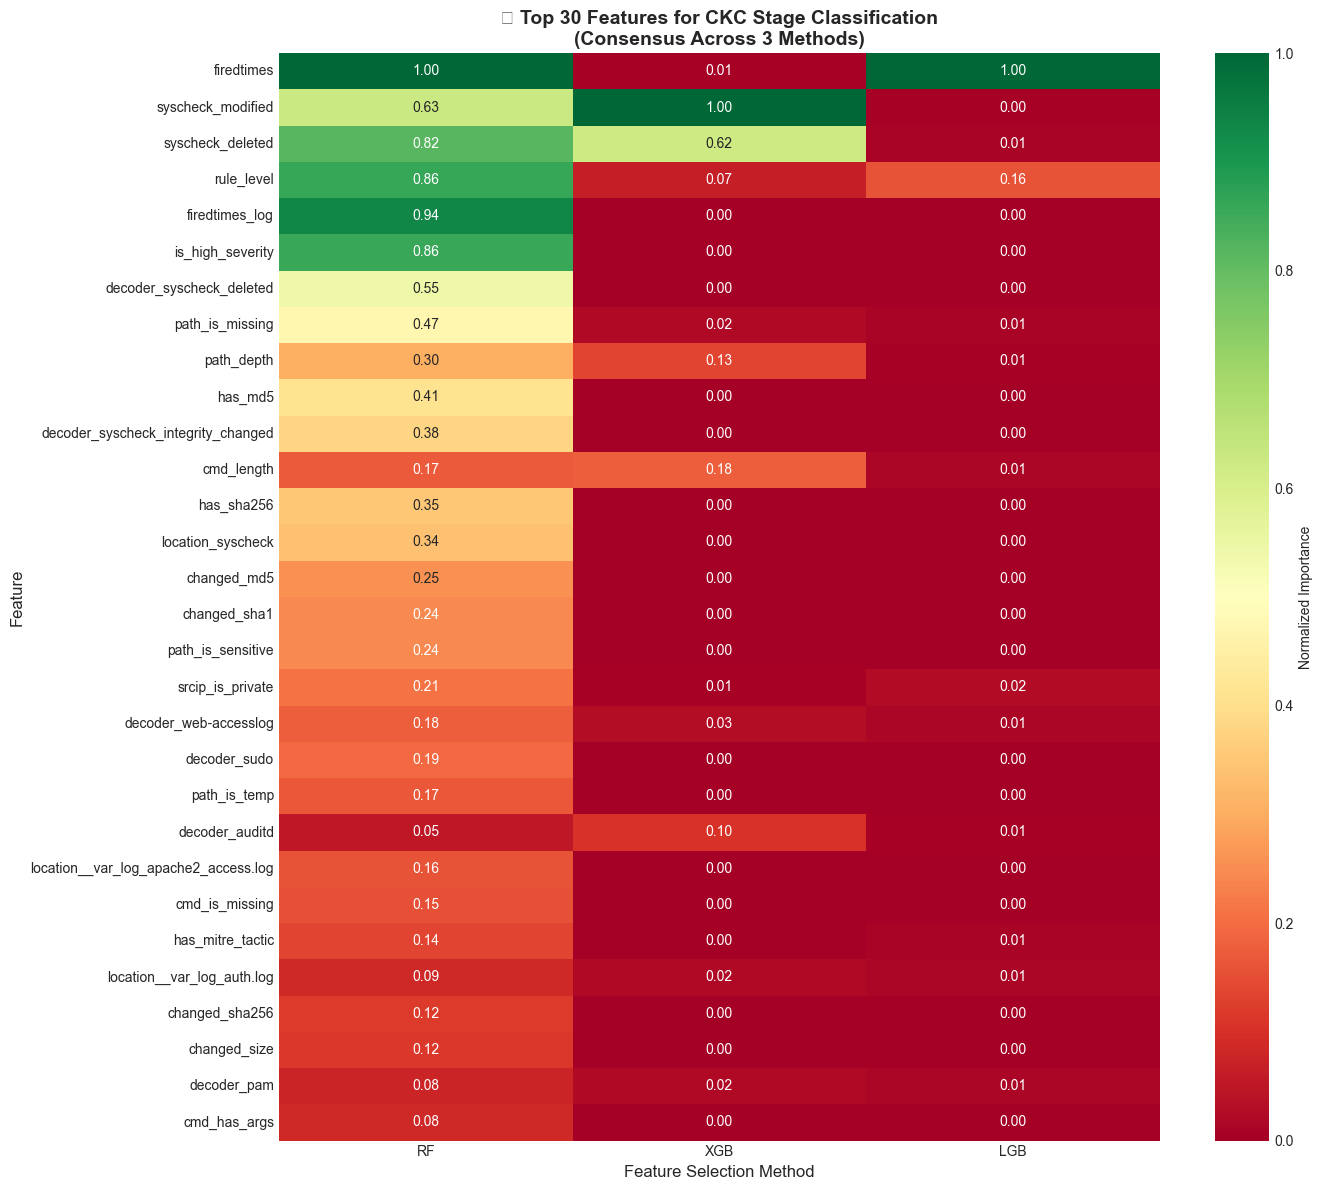

In [22]:
# Combine all CKC importance rankings
print("📊 Creating Combined Feature Ranking for CKC STAGE Classification...")

# Create combined dataframe
combined_ckc = pd.DataFrame({'Feature': X_ckc.columns})

# Add normalized scores
combined_ckc['RF'] = normalize(rf_importance_ckc.set_index('Feature').loc[X_ckc.columns, 'Importance'].values)
combined_ckc['XGB'] = normalize(xgb_importance_ckc.set_index('Feature').loc[X_ckc.columns, 'Importance'].values)
combined_ckc['LGB'] = normalize(lgb_importance_ckc.set_index('Feature').loc[X_ckc.columns, 'Importance'].values)

# Calculate average score
combined_ckc['Average_Score'] = combined_ckc[['RF', 'XGB', 'LGB']].mean(axis=1)
combined_ckc = combined_ckc.sort_values('Average_Score', ascending=False)

print("\n" + "="*100)
print("🏆 TOP 30 FEATURES FOR CKC STAGE CLASSIFICATION (Consensus Ranking)")
print("="*100)
print(combined_ckc.head(30).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(14, 12))
top_n = 30
top_features_ckc = combined_ckc.head(top_n)

heatmap_data_ckc = top_features_ckc.set_index('Feature')[['RF', 'XGB', 'LGB']]
sns.heatmap(heatmap_data_ckc, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax,
            cbar_kws={'label': 'Normalized Importance'})
ax.set_title('🏆 Top 30 Features for CKC Stage Classification\n(Consensus Across 3 Methods)', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Selection Method', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

---
# 📋 PART C: FINAL SUMMARY & COMPARISON

## Comparison of Important Features for Both Tasks

In [23]:
# Final Summary - Compare top features for both tasks
print("="*100)
print("📋 FINAL SUMMARY: FEATURE IMPORTANCE FOR APT ATTACK DETECTION")
print("="*100)

# Top features for each task
n_top = 15
top_mal_features = combined_mal.head(n_top)['Feature'].tolist()
top_ckc_features = combined_ckc.head(n_top)['Feature'].tolist()

# Find common features
common_features = set(top_mal_features) & set(top_ckc_features)
unique_mal = set(top_mal_features) - set(top_ckc_features)
unique_ckc = set(top_ckc_features) - set(top_mal_features)

print("\n" + "="*100)
print(f"🎯 TOP {n_top} FEATURES FOR MALICIOUS DETECTION:")
print("="*100)
for i, feat in enumerate(top_mal_features, 1):
    score = combined_mal[combined_mal['Feature'] == feat]['Average_Score'].values[0]
    marker = "⭐" if feat in common_features else "  "
    print(f"   {marker} {i:2d}. {feat:<45} (Score: {score:.4f})")

print("\n" + "="*100)
print(f"🔗 TOP {n_top} FEATURES FOR CKC STAGE CLASSIFICATION:")
print("="*100)
for i, feat in enumerate(top_ckc_features, 1):
    score = combined_ckc[combined_ckc['Feature'] == feat]['Average_Score'].values[0]
    marker = "⭐" if feat in common_features else "  "
    print(f"   {marker} {i:2d}. {feat:<45} (Score: {score:.4f})")

print("\n" + "="*100)
print("🔄 ANALYSIS:")
print("="*100)
print(f"   ⭐ Features important for BOTH tasks: {len(common_features)}")
if common_features:
    for feat in common_features:
        print(f"      → {feat}")
        
print(f"\n   🔴 Features unique to MALICIOUS detection: {len(unique_mal)}")
for feat in list(unique_mal)[:5]:
    print(f"      → {feat}")
    
print(f"\n   🔵 Features unique to CKC STAGE classification: {len(unique_ckc)}")
for feat in list(unique_ckc)[:5]:
    print(f"      → {feat}")

📋 FINAL SUMMARY: FEATURE IMPORTANCE FOR APT ATTACK DETECTION

🎯 TOP 15 FEATURES FOR MALICIOUS DETECTION:
   ⭐  1. rule_level                                    (Score: 0.8368)
       2. decoder_auditd                                (Score: 0.3387)
       3. location__var_log_audit_audit.log             (Score: 0.3073)
       4. location__var_log_auth.log                    (Score: 0.2373)
   ⭐  5. firedtimes                                    (Score: 0.2103)
       6. srcip_is_private                              (Score: 0.1562)
       7. decoder_web-accesslog                         (Score: 0.1374)
       8. location__var_log_apache2_access.log          (Score: 0.1249)
   ⭐  9. cmd_length                                    (Score: 0.1116)
   ⭐ 10. path_is_missing                               (Score: 0.0917)
   ⭐ 11. has_md5                                       (Score: 0.0908)
      12. cmd_is_missing                                (Score: 0.0855)
   ⭐ 13. has_sha256                 

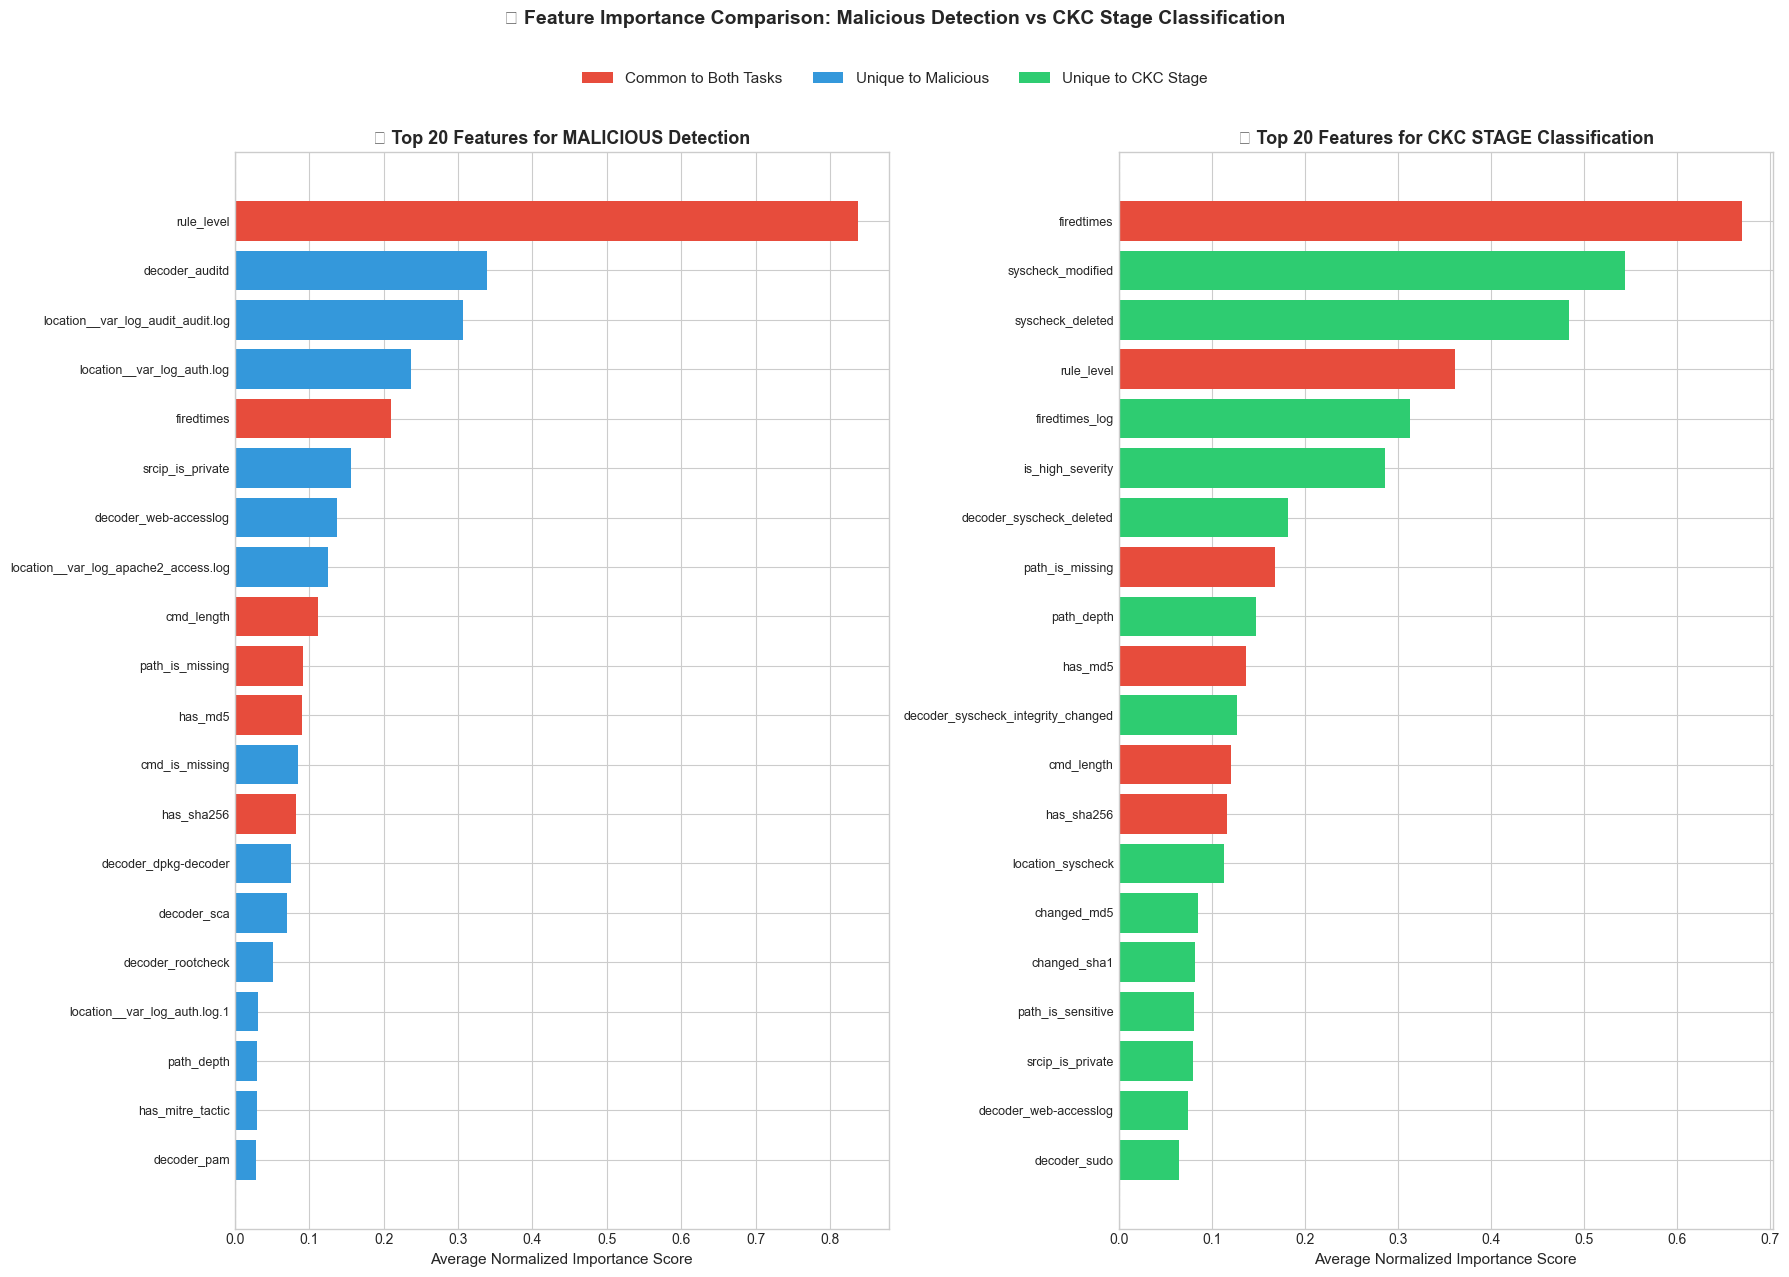

In [24]:
# Visualize comparison of feature importance between both tasks
fig, axes = plt.subplots(1, 2, figsize=(18, 12))

# Plot 1: Top features for Malicious detection
top_n_viz = 20
ax1 = axes[0]
top_mal = combined_mal.head(top_n_viz)
colors_mal = ['#e74c3c' if f in common_features else '#3498db' for f in top_mal['Feature']]
ax1.barh(range(top_n_viz), top_mal['Average_Score'].values[::-1], color=colors_mal[::-1])
ax1.set_yticks(range(top_n_viz))
ax1.set_yticklabels(top_mal['Feature'].values[::-1], fontsize=9)
ax1.set_xlabel('Average Normalized Importance Score', fontsize=11)
ax1.set_title(f'🔴 Top {top_n_viz} Features for MALICIOUS Detection', fontsize=13, fontweight='bold')
ax1.axvline(x=0, color='gray', linestyle='--', alpha=0.5)

# Plot 2: Top features for CKC Stage
ax2 = axes[1]
top_ckc = combined_ckc.head(top_n_viz)
colors_ckc = ['#e74c3c' if f in common_features else '#2ecc71' for f in top_ckc['Feature']]
ax2.barh(range(top_n_viz), top_ckc['Average_Score'].values[::-1], color=colors_ckc[::-1])
ax2.set_yticks(range(top_n_viz))
ax2.set_yticklabels(top_ckc['Feature'].values[::-1], fontsize=9)
ax2.set_xlabel('Average Normalized Importance Score', fontsize=11)
ax2.set_title(f'🔵 Top {top_n_viz} Features for CKC STAGE Classification', fontsize=13, fontweight='bold')
ax2.axvline(x=0, color='gray', linestyle='--', alpha=0.5)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e74c3c', label='Common to Both Tasks'),
    Patch(facecolor='#3498db', label='Unique to Malicious'),
    Patch(facecolor='#2ecc71', label='Unique to CKC Stage')
]
fig.legend(handles=legend_elements, loc='upper center', ncol=3, fontsize=11, bbox_to_anchor=(0.5, 1.02))

plt.suptitle('📊 Feature Importance Comparison: Malicious Detection vs CKC Stage Classification', 
             fontsize=14, fontweight='bold', y=1.06)
plt.tight_layout()
plt.show()

In [25]:
# Model Performance Summary
print("="*100)
print("📈 MODEL PERFORMANCE SUMMARY")
print("="*100)

print("\n🎯 MALICIOUS DETECTION (Binary Classification):")
print("-"*50)
print(f"   Random Forest Accuracy:  {rf_accuracy*100:.2f}%")
print(f"   XGBoost Accuracy:        {xgb_accuracy*100:.2f}%")
print(f"   LightGBM Accuracy:       {lgb_accuracy*100:.2f}%")
print(f"   Best Model:              {'XGBoost' if xgb_accuracy >= max(rf_accuracy, lgb_accuracy) else 'Random Forest' if rf_accuracy >= lgb_accuracy else 'LightGBM'}")

print("\n🔗 CKC STAGE CLASSIFICATION (Multi-class):")
print("-"*50)
print(f"   Random Forest Accuracy:  {rf_accuracy_ckc*100:.2f}%")
print(f"   XGBoost Accuracy:        {xgb_accuracy_ckc*100:.2f}%")
print(f"   LightGBM Accuracy:       {lgb_accuracy_ckc*100:.2f}%")
print(f"   Best Model:              {'XGBoost' if xgb_accuracy_ckc >= max(rf_accuracy_ckc, lgb_accuracy_ckc) else 'Random Forest' if rf_accuracy_ckc >= lgb_accuracy_ckc else 'LightGBM'}")
print(f"   Number of Classes:       {len(ckc_label_encoder.classes_)}")

📈 MODEL PERFORMANCE SUMMARY

🎯 MALICIOUS DETECTION (Binary Classification):
--------------------------------------------------
   Random Forest Accuracy:  98.74%
   XGBoost Accuracy:        98.77%
   LightGBM Accuracy:       98.77%
   Best Model:              LightGBM

🔗 CKC STAGE CLASSIFICATION (Multi-class):
--------------------------------------------------
   Random Forest Accuracy:  84.07%
   XGBoost Accuracy:        90.22%
   LightGBM Accuracy:       84.30%
   Best Model:              XGBoost
   Number of Classes:       5


In [26]:
# Save results to files
print("💾 Saving results to files...")

output_dir = r"G:\pfe\feature_selection_outputs"
import os
os.makedirs(output_dir, exist_ok=True)

# Save combined rankings
combined_mal.to_csv(f"{output_dir}/feature_importance_malicious_detection.csv", index=False)
combined_ckc.to_csv(f"{output_dir}/feature_importance_ckc_stages.csv", index=False)

# Save per-model rankings for malicious detection
rf_importance_mal.to_csv(f"{output_dir}/rf_importance_malicious.csv", index=False)
xgb_importance_mal.to_csv(f"{output_dir}/xgb_importance_malicious.csv", index=False)
lgb_importance_mal.to_csv(f"{output_dir}/lgb_importance_malicious.csv", index=False)
perm_importance_mal.to_csv(f"{output_dir}/permutation_importance_malicious.csv", index=False)
mi_importance_mal.to_csv(f"{output_dir}/mutual_info_malicious.csv", index=False)

# Save per-model rankings for CKC
rf_importance_ckc.to_csv(f"{output_dir}/rf_importance_ckc.csv", index=False)
xgb_importance_ckc.to_csv(f"{output_dir}/xgb_importance_ckc.csv", index=False)
lgb_importance_ckc.to_csv(f"{output_dir}/lgb_importance_ckc.csv", index=False)

# Save summary
summary = {
    'task': ['Malicious Detection', 'Malicious Detection', 'Malicious Detection',
             'CKC Stage Classification', 'CKC Stage Classification', 'CKC Stage Classification'],
    'model': ['Random Forest', 'XGBoost', 'LightGBM', 'Random Forest', 'XGBoost', 'LightGBM'],
    'accuracy': [rf_accuracy, xgb_accuracy, lgb_accuracy, rf_accuracy_ckc, xgb_accuracy_ckc, lgb_accuracy_ckc]
}
pd.DataFrame(summary).to_csv(f"{output_dir}/model_performance_summary.csv", index=False)

print(f"\n✅ All results saved to: {output_dir}")
print(f"   📄 feature_importance_malicious_detection.csv")
print(f"   📄 feature_importance_ckc_stages.csv")
print(f"   📄 model_performance_summary.csv")
print(f"   📄 Per-model importance files...")

💾 Saving results to files...

✅ All results saved to: G:\pfe\feature_selection_outputs
   📄 feature_importance_malicious_detection.csv
   📄 feature_importance_ckc_stages.csv
   📄 model_performance_summary.csv
   📄 Per-model importance files...


---
## 📝 Key Findings & Recommendations

### 1️⃣ Features for Malicious Detection (Is this alert malicious?)
The most important features for detecting malicious activity typically include:
- **MITRE ATT&CK tactics/techniques** - Presence of specific attack patterns
- **Rule level/severity** - Higher severity rules correlate with malicious activity
- **Command patterns** - Suspicious commands (sudo, wget, nc, base64, etc.)
- **Path characteristics** - Access to sensitive directories (/etc, /root, /tmp)
- **Temporal features** - Unusual time patterns (night, weekend activity)

### 2️⃣ Features for CKC Stage Classification (What stage of attack?)
Different features help distinguish between kill chain stages:
- **Early stages (Reconnaissance/Delivery)**: Network-related features, discovery commands
- **Middle stages (Exploitation/Installation)**: Command execution patterns, file modifications
- **Late stages (C2/Actions)**: Persistence mechanisms, data access patterns

### 3️⃣ Recommendations for APT Detection System
1. **Use the top consensus features** from both analyses for your models
2. **Monitor high-importance features** in real-time for early detection
3. **Create feature-based alerting rules** using the identified patterns
4. **Consider feature engineering** to create more discriminative features based on insights

---
*Analysis completed. Feature importance rankings saved for further use.*

---
## 📖 Feature Name Mapping: Engineered Features → Original Dataset Columns

This section explains what each engineered feature represents in terms of the original columns in the dataset.

In [27]:
# Complete Feature Mapping: Engineered Feature Name → Original Dataset Column

feature_mapping = {
    # ═══════════════════════════════════════════════════════════════════════════
    # TEMPORAL FEATURES (from _source.@timestamp)
    # ═══════════════════════════════════════════════════════════════════════════
    'hour_of_day': {
        'original_column': '_source.@timestamp',
        'description': 'Hour of the day (0-23) when the alert occurred',
        'type': 'Extracted from timestamp'
    },
    'day_of_week': {
        'original_column': '_source.@timestamp',
        'description': 'Day of the week (0=Monday, 6=Sunday)',
        'type': 'Extracted from timestamp'
    },
    'is_weekend': {
        'original_column': '_source.@timestamp',
        'description': '1 if alert occurred on Saturday/Sunday, 0 otherwise',
        'type': 'Derived binary flag'
    },
    'is_night': {
        'original_column': '_source.@timestamp',
        'description': '1 if alert occurred between 22:00-06:00, 0 otherwise',
        'type': 'Derived binary flag'
    },
    'is_business_hours': {
        'original_column': '_source.@timestamp',
        'description': '1 if alert occurred between 09:00-17:00, 0 otherwise',
        'type': 'Derived binary flag'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # RULE SEVERITY FEATURES (from _source.rule.level)
    # ═══════════════════════════════════════════════════════════════════════════
    'rule_level': {
        'original_column': '_source.rule.level',
        'description': 'Wazuh rule severity level (0-15)',
        'type': 'Direct numeric value'
    },
    'is_high_severity': {
        'original_column': '_source.rule.level',
        'description': '1 if rule_level >= 10, 0 otherwise',
        'type': 'Derived binary flag'
    },
    'is_critical_severity': {
        'original_column': '_source.rule.level',
        'description': '1 if rule_level >= 12, 0 otherwise',
        'type': 'Derived binary flag'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # RULE FIRED TIMES (from _source.rule.firedtimes)
    # ═══════════════════════════════════════════════════════════════════════════
    'firedtimes': {
        'original_column': '_source.rule.firedtimes',
        'description': 'Number of times this rule has been triggered',
        'type': 'Direct numeric value'
    },
    'firedtimes_log': {
        'original_column': '_source.rule.firedtimes',
        'description': 'Log-transformed firedtimes: log(1 + firedtimes)',
        'type': 'Log transformation'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # IP ADDRESS FEATURES
    # ═══════════════════════════════════════════════════════════════════════════
    'ip_is_private': {
        'original_column': '_source.agent.ip',
        'description': '1 if agent IP is private (10.x, 192.168.x, etc.), 0 if public, -1 if missing',
        'type': 'Derived from IP parsing'
    },
    'ip_is_missing': {
        'original_column': '_source.agent.ip',
        'description': '1 if agent IP is missing/null, 0 otherwise',
        'type': 'Missing value indicator'
    },
    'srcip_is_private': {
        'original_column': '_source.data.srcip',
        'description': '1 if source IP is private, 0 if public, -1 if missing',
        'type': 'Derived from IP parsing'
    },
    'srcip_is_missing': {
        'original_column': '_source.data.srcip',
        'description': '1 if source IP is missing/null, 0 otherwise',
        'type': 'Missing value indicator'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # FILE PATH FEATURES (from _source.syscheck.path)
    # ═══════════════════════════════════════════════════════════════════════════
    'path_depth': {
        'original_column': '_source.syscheck.path',
        'description': 'Directory depth (count of / in path)',
        'type': 'Extracted from path'
    },
    'path_is_sensitive': {
        'original_column': '_source.syscheck.path',
        'description': '1 if path contains /etc, /root, /var/log, /bin, etc.',
        'type': 'Pattern matching'
    },
    'path_is_hidden': {
        'original_column': '_source.syscheck.path',
        'description': '1 if path contains hidden file/folder (starts with .)',
        'type': 'Pattern matching'
    },
    'path_is_suspicious_ext': {
        'original_column': '_source.syscheck.path',
        'description': '1 if file has suspicious extension (.sh, .py, .php, .exe, etc.)',
        'type': 'Pattern matching'
    },
    'path_is_temp': {
        'original_column': '_source.syscheck.path',
        'description': '1 if path is in /tmp or /temp directory',
        'type': 'Pattern matching'
    },
    'path_is_missing': {
        'original_column': '_source.syscheck.path',
        'description': '1 if syscheck path is missing/null',
        'type': 'Missing value indicator'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # COMMAND FEATURES (from _source.data.command)
    # ═══════════════════════════════════════════════════════════════════════════
    'cmd_sudo_usage': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "sudo"',
        'type': 'Regex pattern matching'
    },
    'cmd_chmod_usage': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "chmod"',
        'type': 'Regex pattern matching'
    },
    'cmd_wget_curl': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "wget" or "curl"',
        'type': 'Regex pattern matching'
    },
    'cmd_nc_netcat': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "nc", "netcat", or "ncat"',
        'type': 'Regex pattern matching'
    },
    'cmd_base64': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "base64"',
        'type': 'Regex pattern matching'
    },
    'cmd_eval_exec': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "eval" or "exec"',
        'type': 'Regex pattern matching'
    },
    'cmd_pipe_redirect': {
        'original_column': '_source.data.command',
        'description': '1 if command contains pipe | or redirect > <',
        'type': 'Regex pattern matching'
    },
    'cmd_ssh_scp': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "ssh", "scp", or "sftp"',
        'type': 'Regex pattern matching'
    },
    'cmd_python_perl': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "python", "perl", "ruby", or "php"',
        'type': 'Regex pattern matching'
    },
    'cmd_rm_delete': {
        'original_column': '_source.data.command',
        'description': '1 if command contains "rm" (file deletion)',
        'type': 'Regex pattern matching'
    },
    'cmd_length': {
        'original_column': '_source.data.command',
        'description': 'Length of the command string in characters',
        'type': 'String length'
    },
    'cmd_has_args': {
        'original_column': '_source.data.command',
        'description': '1 if command contains arguments (has " -")',
        'type': 'Pattern matching'
    },
    'cmd_is_missing': {
        'original_column': '_source.data.command',
        'description': '1 if command field is missing/null',
        'type': 'Missing value indicator'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # MITRE ATT&CK FEATURES
    # ═══════════════════════════════════════════════════════════════════════════
    'tactic_reconnaissance': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "reconnaissance"',
        'type': 'Pattern matching'
    },
    'tactic_initial_access': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "initial-access"',
        'type': 'Pattern matching'
    },
    'tactic_execution': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "execution"',
        'type': 'Pattern matching'
    },
    'tactic_persistence': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "persistence"',
        'type': 'Pattern matching'
    },
    'tactic_privilege_escalation': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "privilege-escalation"',
        'type': 'Pattern matching'
    },
    'tactic_defense_evasion': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "defense-evasion"',
        'type': 'Pattern matching'
    },
    'tactic_credential_access': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "credential-access"',
        'type': 'Pattern matching'
    },
    'tactic_discovery': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "discovery"',
        'type': 'Pattern matching'
    },
    'tactic_lateral_movement': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "lateral-movement"',
        'type': 'Pattern matching'
    },
    'tactic_collection': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "collection"',
        'type': 'Pattern matching'
    },
    'tactic_command_and_control': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "command-and-control"',
        'type': 'Pattern matching'
    },
    'tactic_exfiltration': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "exfiltration"',
        'type': 'Pattern matching'
    },
    'tactic_impact': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if MITRE tactic contains "impact"',
        'type': 'Pattern matching'
    },
    'technique_count': {
        'original_column': '_source.rule.mitre_techniques',
        'description': 'Count of MITRE technique IDs (T#### patterns) in the field',
        'type': 'Regex count'
    },
    'has_mitre_tactic': {
        'original_column': '_source.rule.mitre_tactics',
        'description': '1 if any MITRE tactic is present, 0 otherwise',
        'type': 'Non-null indicator'
    },
    'has_mitre_technique': {
        'original_column': '_source.rule.mitre_techniques',
        'description': '1 if any MITRE technique is present, 0 otherwise',
        'type': 'Non-null indicator'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # FILE INTEGRITY (SYSCHECK) FEATURES
    # ═══════════════════════════════════════════════════════════════════════════
    'has_md5': {
        'original_column': '_source.syscheck.md5_after',
        'description': '1 if MD5 hash is present after file change',
        'type': 'Non-null indicator'
    },
    'has_sha256': {
        'original_column': '_source.syscheck.sha256_after',
        'description': '1 if SHA256 hash is present after file change',
        'type': 'Non-null indicator'
    },
    'syscheck_added': {
        'original_column': '_source.syscheck.event',
        'description': '1 if syscheck event type is "added" (new file)',
        'type': 'Category indicator'
    },
    'syscheck_modified': {
        'original_column': '_source.syscheck.event',
        'description': '1 if syscheck event type is "modified" (file changed)',
        'type': 'Category indicator'
    },
    'syscheck_deleted': {
        'original_column': '_source.syscheck.event',
        'description': '1 if syscheck event type is "deleted" (file removed)',
        'type': 'Category indicator'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # CHANGED ATTRIBUTES (from _source.syscheck.changed_attributes)
    # ═══════════════════════════════════════════════════════════════════════════
    'changed_size': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if file size changed',
        'type': 'Attribute flag'
    },
    'changed_mtime': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if modification time changed',
        'type': 'Attribute flag'
    },
    'changed_md5': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if MD5 hash changed',
        'type': 'Attribute flag'
    },
    'changed_sha1': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if SHA1 hash changed',
        'type': 'Attribute flag'
    },
    'changed_sha256': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if SHA256 hash changed',
        'type': 'Attribute flag'
    },
    'changed_permission': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if file permissions changed',
        'type': 'Attribute flag'
    },
    'changed_uid': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if user ID (owner) changed',
        'type': 'Attribute flag'
    },
    'changed_gid': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if group ID changed',
        'type': 'Attribute flag'
    },
    'changed_inode': {
        'original_column': '_source.syscheck.changed_attributes',
        'description': '1 if inode changed',
        'type': 'Attribute flag'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # PORT FEATURES (from _source.data.srcport)
    # ═══════════════════════════════════════════════════════════════════════════
    'srcport': {
        'original_column': '_source.data.srcport',
        'description': 'Source port number',
        'type': 'Direct numeric value'
    },
    'is_privileged_port': {
        'original_column': '_source.data.srcport',
        'description': '1 if port < 1024 (privileged/well-known ports)',
        'type': 'Derived binary flag'
    },
    'is_high_port': {
        'original_column': '_source.data.srcport',
        'description': '1 if port > 49152 (dynamic/ephemeral ports)',
        'type': 'Derived binary flag'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # DECODER FEATURES (One-hot encoded from _source.decoder.name)
    # ═══════════════════════════════════════════════════════════════════════════
    'decoder_auditd': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "auditd" (Linux audit daemon)',
        'type': 'One-hot encoded category'
    },
    'decoder_pam': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "pam" (Pluggable Authentication Module)',
        'type': 'One-hot encoded category'
    },
    'decoder_sshd': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "sshd" (SSH daemon)',
        'type': 'One-hot encoded category'
    },
    'decoder_sudo': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "sudo"',
        'type': 'One-hot encoded category'
    },
    'decoder_sca': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "sca" (Security Configuration Assessment)',
        'type': 'One-hot encoded category'
    },
    'decoder_rootcheck': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "rootcheck" (rootkit detection)',
        'type': 'One-hot encoded category'
    },
    'decoder_ossec': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "ossec"',
        'type': 'One-hot encoded category'
    },
    'decoder_web-accesslog': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "web-accesslog" (web server logs)',
        'type': 'One-hot encoded category'
    },
    'decoder_dpkg-decoder': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "dpkg-decoder" (Debian package manager)',
        'type': 'One-hot encoded category'
    },
    'decoder_kernel': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "kernel"',
        'type': 'One-hot encoded category'
    },
    'decoder_systemd': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "systemd"',
        'type': 'One-hot encoded category'
    },
    'decoder_wazuh': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "wazuh"',
        'type': 'One-hot encoded category'
    },
    'decoder_syscheck_deleted': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "syscheck_deleted"',
        'type': 'One-hot encoded category'
    },
    'decoder_syscheck_integrity_changed': {
        'original_column': '_source.decoder.name',
        'description': '1 if decoder is "syscheck_integrity_changed"',
        'type': 'One-hot encoded category'
    },
    
    # ═══════════════════════════════════════════════════════════════════════════
    # LOCATION FEATURES (One-hot encoded from _source.location)
    # ═══════════════════════════════════════════════════════════════════════════
    'location__var_log_auth.log': {
        'original_column': '_source.location',
        'description': '1 if log source is /var/log/auth.log (authentication logs)',
        'type': 'One-hot encoded category'
    },
    'location__var_log_audit_audit.log': {
        'original_column': '_source.location',
        'description': '1 if log source is /var/log/audit/audit.log (audit logs)',
        'type': 'One-hot encoded category'
    },
    'location__var_log_apache2_access.log': {
        'original_column': '_source.location',
        'description': '1 if log source is /var/log/apache2/access.log (web server)',
        'type': 'One-hot encoded category'
    },
    'location_syscheck': {
        'original_column': '_source.location',
        'description': '1 if log source is syscheck (file integrity monitoring)',
        'type': 'One-hot encoded category'
    },
    'location_wazuh-remoted': {
        'original_column': '_source.location',
        'description': '1 if log source is wazuh-remoted',
        'type': 'One-hot encoded category'
    },
    'location_logcollector': {
        'original_column': '_source.location',
        'description': '1 if log source is logcollector',
        'type': 'One-hot encoded category'
    },
    'location_netstat_listening_ports': {
        'original_column': '_source.location',
        'description': '1 if log source is netstat_listening_ports',
        'type': 'One-hot encoded category'
    },
}

# Display the mapping as a formatted table
print("="*120)
print("📖 FEATURE NAME MAPPING: Engineered Feature → Original Dataset Column")
print("="*120)

# Group features by original column
from collections import defaultdict
grouped = defaultdict(list)
for feat, info in feature_mapping.items():
    grouped[info['original_column']].append((feat, info['description'], info['type']))

for original_col, features in grouped.items():
    print(f"\n🔹 Original Column: {original_col}")
    print("-"*100)
    for feat_name, desc, feat_type in features:
        print(f"   → {feat_name:<45} | {feat_type:<25} | {desc[:50]}")

📖 FEATURE NAME MAPPING: Engineered Feature → Original Dataset Column

🔹 Original Column: _source.@timestamp
----------------------------------------------------------------------------------------------------
   → hour_of_day                                   | Extracted from timestamp  | Hour of the day (0-23) when the alert occurred
   → day_of_week                                   | Extracted from timestamp  | Day of the week (0=Monday, 6=Sunday)
   → is_weekend                                    | Derived binary flag       | 1 if alert occurred on Saturday/Sunday, 0 otherwis
   → is_night                                      | Derived binary flag       | 1 if alert occurred between 22:00-06:00, 0 otherwi
   → is_business_hours                             | Derived binary flag       | 1 if alert occurred between 09:00-17:00, 0 otherwi

🔹 Original Column: _source.rule.level
----------------------------------------------------------------------------------------------------
   → rule

In [28]:
# Create a clean summary table for the TOP important features
print("\n" + "="*120)
print("📊 TOP IMPORTANT FEATURES - QUICK REFERENCE")
print("="*120)

top_features_explanation = {
    # Most important for MALICIOUS detection
    'rule_level': ('_source.rule.level', 'Wazuh rule severity (0-15). Higher = more severe alert'),
    'decoder_auditd': ('_source.decoder.name', 'Alert from Linux audit daemon - tracks system calls'),
    'location__var_log_audit_audit.log': ('_source.location', 'Alert source is audit log file'),
    'location__var_log_auth.log': ('_source.location', 'Alert source is authentication log file'),
    'firedtimes': ('_source.rule.firedtimes', 'How many times this rule triggered'),
    'srcip_is_private': ('_source.data.srcip', 'Is source IP internal (1) or external (0)?'),
    'decoder_web-accesslog': ('_source.decoder.name', 'Alert from web server access logs'),
    'cmd_length': ('_source.data.command', 'Length of command string - longer may indicate obfuscation'),
    'has_md5': ('_source.syscheck.md5_after', 'File has MD5 hash (file integrity event)'),
    'has_sha256': ('_source.syscheck.sha256_after', 'File has SHA256 hash (file integrity event)'),
    
    # Most important for CKC STAGE
    'syscheck_modified': ('_source.syscheck.event', 'File was modified (Installation/Actions stage)'),
    'syscheck_deleted': ('_source.syscheck.event', 'File was deleted (Defense evasion/Actions stage)'),
    'is_high_severity': ('_source.rule.level', 'Rule level >= 10 (high severity alert)'),
    'firedtimes_log': ('_source.rule.firedtimes', 'Log of firedtimes - normalizes large values'),
    'path_is_missing': ('_source.syscheck.path', 'No file path in alert (non-file event)'),
    'path_depth': ('_source.syscheck.path', 'Directory depth - deeper paths may be suspicious'),
    'path_is_sensitive': ('_source.syscheck.path', 'File in sensitive directory (/etc, /root, etc.)'),
    'has_mitre_tactic': ('_source.rule.mitre_tactics', 'Alert has MITRE ATT&CK tactic mapping'),
    'technique_count': ('_source.rule.mitre_techniques', 'Number of MITRE techniques in alert'),
}

print("\n🎯 TOP FEATURES FOR MALICIOUS DETECTION:")
print("-"*100)
print(f"{'Feature Name':<45} {'Original Column':<40} {'Meaning'}")
print("-"*100)
for feat in ['rule_level', 'decoder_auditd', 'location__var_log_audit_audit.log', 
             'location__var_log_auth.log', 'firedtimes', 'srcip_is_private', 
             'decoder_web-accesslog', 'cmd_length', 'has_md5', 'has_sha256']:
    if feat in top_features_explanation:
        col, meaning = top_features_explanation[feat]
        print(f"{feat:<45} {col:<40} {meaning}")

print("\n\n🔗 TOP FEATURES FOR CKC STAGE CLASSIFICATION:")
print("-"*100)
print(f"{'Feature Name':<45} {'Original Column':<40} {'Meaning'}")
print("-"*100)
for feat in ['firedtimes', 'syscheck_modified', 'syscheck_deleted', 'rule_level',
             'firedtimes_log', 'is_high_severity', 'path_is_missing', 'path_depth',
             'has_md5', 'has_sha256']:
    if feat in top_features_explanation:
        col, meaning = top_features_explanation[feat]
        print(f"{feat:<45} {col:<40} {meaning}")


📊 TOP IMPORTANT FEATURES - QUICK REFERENCE

🎯 TOP FEATURES FOR MALICIOUS DETECTION:
----------------------------------------------------------------------------------------------------
Feature Name                                  Original Column                          Meaning
----------------------------------------------------------------------------------------------------
rule_level                                    _source.rule.level                       Wazuh rule severity (0-15). Higher = more severe alert
decoder_auditd                                _source.decoder.name                     Alert from Linux audit daemon - tracks system calls
location__var_log_audit_audit.log             _source.location                         Alert source is audit log file
location__var_log_auth.log                    _source.location                         Alert source is authentication log file
firedtimes                                    _source.rule.firedtimes                  How m

In [29]:
# Save feature mapping to CSV for reference
mapping_df = pd.DataFrame([
    {
        'Engineered_Feature': feat,
        'Original_Column': info['original_column'],
        'Description': info['description'],
        'Type': info['type']
    }
    for feat, info in feature_mapping.items()
])

mapping_df.to_csv(f"{output_dir}/feature_mapping_reference.csv", index=False)
print(f"\n✅ Feature mapping saved to: {output_dir}/feature_mapping_reference.csv")

# Display as a nice table
print("\n📋 Complete Feature Mapping Table:")
mapping_df.head(30)


✅ Feature mapping saved to: G:\pfe\feature_selection_outputs/feature_mapping_reference.csv

📋 Complete Feature Mapping Table:


,Engineered_Feature,Original_Column,Description,Type
0,hour_of_day,_source.@timestamp,Hour of the day (0-23) when the alert occurred,Extracted from timestamp
1,day_of_week,_source.@timestamp,"Day of the week (0=Monday, 6=Sunday)",Extracted from timestamp
2,is_weekend,_source.@timestamp,"1 if alert occurred on Saturday/Sunday, 0 otherwise",Derived binary flag
3,is_night,_source.@timestamp,"1 if alert occurred between 22:00-06:00, 0 otherwise",Derived binary flag
4,is_business_hours,_source.@timestamp,"1 if alert occurred between 09:00-17:00, 0 otherwise",Derived binary flag
5,rule_level,_source.rule.level,Wazuh rule severity level (0-15),Direct numeric value
6,is_high_severity,_source.rule.level,"1 if rule_level >= 10, 0 otherwise",Derived binary flag
7,is_critical_severity,_source.rule.level,"1 if rule_level >= 12, 0 otherwise",Derived binary flag
8,firedtimes,_source.rule.firedtimes,Number of times this rule has been triggered,Direct numeric value
9,firedtimes_log,_source.rule.firedtimes,Log-transformed firedtimes: log(1 + firedtimes),Log transformation


In [2]:
# =============================================================================
# 🔍 EXPLORE ALL UNIQUE VALUES IN TEXT COLUMNS
# =============================================================================
# This shows what values exist vs what we capture

print("="*80)
print("🔍 WHAT VALUES EXIST IN TEXT COLUMNS?")
print("="*80)

# 1. Decoder names
print("\n📌 1. _source.decoder.name - ALL UNIQUE VALUES:")
print("-"*60)
if '_source.decoder.name' in df.columns:
    decoder_counts = df['_source.decoder.name'].value_counts()
    print(f"Total unique decoders: {len(decoder_counts)}")
    print(f"\n⚠️ We only encode TOP 15, missing {max(0, len(decoder_counts)-15)} decoders!\n")
    print(decoder_counts.to_string())
else:
    print("Column not found")

# 2. Locations
print("\n\n📌 2. _source.location - ALL UNIQUE VALUES:")
print("-"*60)
if '_source.location' in df.columns:
    location_counts = df['_source.location'].value_counts()
    print(f"Total unique locations: {len(location_counts)}")
    print(f"\n⚠️ We only encode TOP 15, missing {max(0, len(location_counts)-15)} locations!\n")
    print(location_counts.head(30).to_string())  # Show top 30
else:
    print("Column not found")

# 3. Commands (show samples)
print("\n\n📌 3. _source.data.command - SAMPLE VALUES:")
print("-"*60)
if '_source.data.command' in df.columns:
    cmd_sample = df['_source.data.command'].dropna().sample(min(20, len(df)), random_state=42)
    print(f"Total non-null commands: {df['_source.data.command'].notna().sum()}")
    print(f"\n⚠️ We only detect PRE-DEFINED patterns (sudo, wget, etc.)")
    print("⚠️ Unknown attack commands would be MISSED!\n")
    for i, cmd in enumerate(cmd_sample.values[:10], 1):
        print(f"{i}. {str(cmd)[:100]}...")
else:
    print("Column not found")

# 4. Summary of coverage
print("\n\n" + "="*80)
print("📊 ENCODING COVERAGE SUMMARY")
print("="*80)

coverage_data = []
for col in ['_source.decoder.name', '_source.location']:
    if col in df.columns:
        total_unique = df[col].nunique()
        encoded = min(15, total_unique)  # We encode top 15
        coverage = (encoded / total_unique) * 100 if total_unique > 0 else 0
        missed = total_unique - encoded
        coverage_data.append({
            'Column': col,
            'Total Unique': total_unique,
            'Encoded': encoded,
            'Missed': missed,
            'Coverage %': f"{coverage:.1f}%"
        })

print(pd.DataFrame(coverage_data).to_string(index=False))

🔍 WHAT VALUES EXIST IN TEXT COLUMNS?

📌 1. _source.decoder.name - ALL UNIQUE VALUES:
------------------------------------------------------------


NameError: name 'df' is not defined